**Load Data**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
from scipy.stats import gmean
from sklearn.impute import KNNImputer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import StackingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor
import itertools
from sklearn.model_selection import cross_validate, KFold
import plotly.graph_objects as go

In [2]:
df = pd.read_csv('quang_ninh_wqi_v8.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1110 entries, 0 to 1109
Data columns (total 43 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Location  1110 non-null   object
 1   ID        1106 non-null   object
 2   Month     1110 non-null   object
 3   Temp      1110 non-null   object
 4   pH        1110 non-null   object
 5   DO        1110 non-null   object
 6   Sal       954 non-null    object
 7   Turb      954 non-null    object
 8   TSS       1110 non-null   object
 9   COD       1110 non-null   object
 10  BOD5      1110 non-null   object
 11  SO4       156 non-null    object
 12  NO3       1110 non-null   object
 13  NO2       1110 non-null   object
 14  NH4       1110 non-null   object
 15  PO4       1110 non-null   object
 16  MBAS      954 non-null    object
 17  Cyan      954 non-null    object
 18  Fluor     954 non-null    object
 19  Cl        1110 non-null   object
 20  OilFat    1110 non-null   object
 21  Coliform  1110

Location: Sampling location

ID: Unique sample identifier

Month: Monitoring month

Temp: Water temperature in Celsius

pH: pH level

DO: Dissolved Oxygen in mg/L

Sal: Salinity of water

Turb: Water turbidity

TSS: Total Suspended Solids in mg/L

COD: Chemical Oxygen Demand in mg/L

BOD5: Biochemical Oxygen Demand over 5 days in mg/L

SO4: Sulfate concentration in mg/L

NO3: Nitrate concentration in mg/L

NO2: Nitrite concentration in mg/L

NH4: Ammonium concentration in mg/L

PO4: Phosphate concentration in mg/L

MBAS: Surfactant content (MBAS method)

Cyan: Cyanide concentration

Fluor: Fluoride concentration

Cl: Chloride concentration in mg/L

OilFat: Total oil and fat content in mg/L

Coliform: Coliform bacteria count (MPN/100ml)

EColi: E. Coli bacteria count

As: Arsenic concentration in mg/L

Hg: Mercury concentration in mg/L

Pb: Lead concentration in mg/L

Cd: Cadmium concentration in mg/L

Fe: Iron concentration in mg/L

Mn: Manganese concentration

Cu: Copper concentration

Ni: Nickel concentration

Zn: Zinc concentration

Cr: Chromium concentration

CrVI: Hexavalent Chromium concentration

Phenol: Total phenol content

RadAlpha: Total alpha radioactivity

RadBeta: Total beta radioactivity

Aldrin: Aldrin pesticide concentration

BHC: BHC pesticide concentration

Dieldrin: Dieldrin pesticide concentration

DDTs: DDT and its derivatives concentration

Heptach: Heptachlor & Heptachloreproxide concentration

TOC: Total Organic Carbon

# 1. Data Pre-processing


---

**Drop irrelevant columns**

In [4]:
df_dropped = df.drop([
    'Location', 'ID', 'Month', 'Sal', 'Turb', 'TSS', 'SO4', 'MBAS', 'Cyan', 'Fluor',
    'Cl', 'OilFat', 'Fe', 'Mn', 'Cu', 'Ni', 'Zn', 'Cr', 'Phenol',
    'RadAlpha', 'RadBeta'
], axis=1)

Drop some columns which don't impact to WQI scores

## 1.1 Data type conversion

In [ ]:
non_numeric_values_dropped = {}
for col in df_dropped.columns:
    # Create a boolean series for values that are neither numeric nor NaN
    is_not_numeric_and_not_nan = df_dropped[col].apply(lambda x: not (isinstance(x, (int, float)) or pd.isna(x)))

    if is_not_numeric_and_not_nan.any():
        # Use this boolean series to filter the original column
        non_numeric_entries = df_dropped[col][is_not_numeric_and_not_nan]
        non_numeric_values_dropped[col] = non_numeric_entries.unique().tolist()

if non_numeric_values_dropped:
    print("Non-numeric values found in df_dropped (excluding NaN):")
    for col, values in non_numeric_values_dropped.items():
        print(f"- {col}: {values}")
else:
    print("No non-numeric values found in df_dropped (excluding NaN).")

Non-numeric values found (excluding NaN):

| Value     | Meaning / Issue                                           |
|-----------|-----------------------------------------------------------|
| `x`       | Missing value (NaN)                                       |
| `X`       | Missing value (NaN)                                       |
| `<x`      | Missing / below detection                                  |
| `x,x  `   | Invalid numeric format (string instead of number)         |
| `KCM`     | Special missing value / placeholder                       |


In [ ]:
def handle_less_than_numeric(val):
    # If the value is a string
    if isinstance(val, str):
        val = val.strip()
        # If it matches the pattern "<x" or "<x.y"
        match = re.fullmatch(r'<\s*([0-9,]*\.?[0-9]+)', val)
        if match:
            x_str = match.group(1).replace(',', '.')
            return float(x_str)
        # If it's a numeric string with comma or dot
        try:
            return float(val.replace(',', '.'))
        except ValueError:
            return val
    # If it's already a number, keep as is
    elif isinstance(val, (int, float)):
        return val
    # Other values remain unchanged
    return val

# Apply the conversion to handle "<" and numeric strings
df_parsed = df_dropped.applymap(handle_less_than_numeric)

Cells with values less than x will be converted to type x, and cells with values using a comma instead of a dot will be converted to use a dot.

In [ ]:
df_cleaned = df_parsed.replace('KCM', np.nan)

KCM: Value could not be measured. These cells will be converted into NaN

In [ ]:
df_replaced_X = df_cleaned.replace('X', np.nan)
df_replaced_x = df_replaced_X.replace('x', np.nan)

Some cells contain 'x' instead of being empty, so the missing values were standardized and the number of missing values was calculated.


In [ ]:
def convert_column_type(col):
    # Remove NaN to check
    non_na = col.dropna()

    # Check if all are numbers
    if non_na.apply(lambda x: isinstance(x, (int, float))).all():
        return col.astype(float)
    else:
        return col.astype('category')

# Convert all to numeric (if not a number → NaN)
df_typed = df_replaced_x.apply(convert_column_type)

Convert column data types to appropriate types

In [ ]:
df_typed.info()

The dataset has already been converted to the appropriate data types

## 1.2 Missing Values and Data Splitting


---

In [ ]:
df_missing75_removed = df_typed.drop([
    'Aldrin', 'BHC', 'Dieldrin', 'DDTs', 'Heptach', 'TOC'
], axis=1)

Columns with about 75% missing values were removed.

In [73]:
df_rows_cleaned = df_missing75_removed.dropna(how='all')

print(f"Original DataFrame shape: {df_missing75_removed.shape}")
print(f"DataFrame shape after dropping rows with all NaN: {df_rows_cleaned.shape}")
print(f"{df_missing75_removed.shape[0]- df_rows_cleaned.shape[0]} records containing all NaN values were removed.")

Original DataFrame shape: (1110, 16)
DataFrame shape after dropping rows with all NaN: (1101, 16)
9 records containing all NaN values were removed.


I chose to remove records containing NaN values because there are only 9 such records, which is negligible compared to the overall dataset, and removing them will not significantly affect the analysis.

In [74]:
clean_indices = df_rows_cleaned.dropna().index
_, test_indices = train_test_split(clean_indices, test_size=0.24, random_state=42)
test_data = df_rows_cleaned.loc[test_indices]
train_data = df_rows_cleaned.drop(test_indices)

Split dataset to training and testing

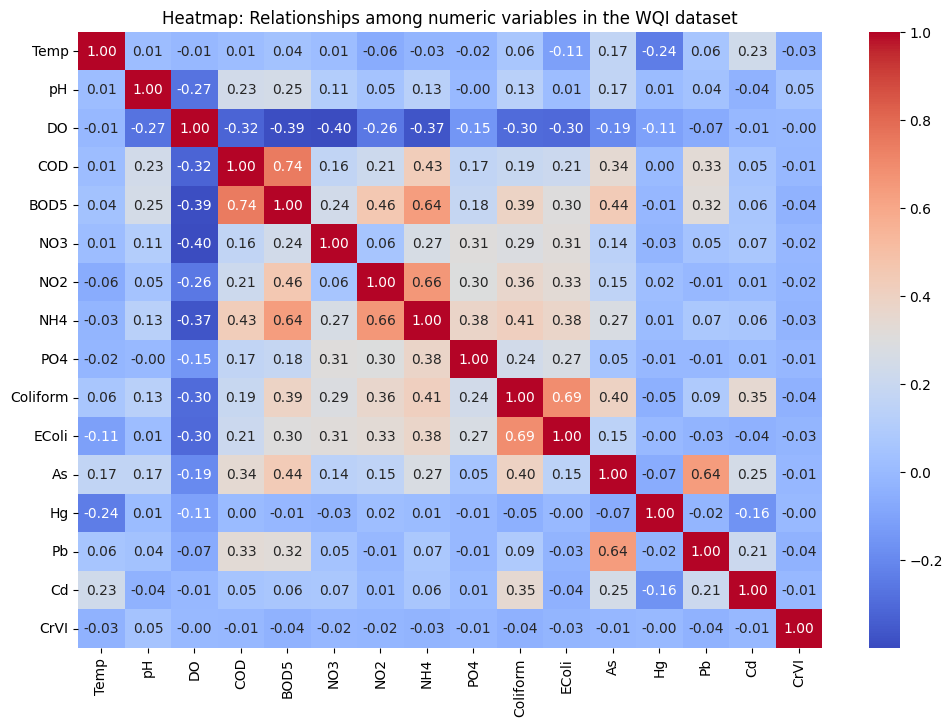

In [75]:
# Select numeric columns
numeric_cols = train_data.select_dtypes(include=['int64', 'float64']).columns
df_numeric = train_data[numeric_cols]

# Compute the correlation matrix
corr_matrix = df_numeric.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Relationships among numeric variables in the WQI dataset")
plt.show()

In [76]:
num_cols_to_impute = ['EColi', 'CrVI']

other_num_cols = [col for col in train_data.select_dtypes(include='number').columns
                  if col not in num_cols_to_impute]

df_KNNfilled = train_data.copy()

imputer = KNNImputer(n_neighbors=5)

df_KNNfilled[num_cols_to_impute] = imputer.fit_transform(
    df_KNNfilled[num_cols_to_impute + other_num_cols]
)[:, :len(num_cols_to_impute)]

I choose KNN because it better preserves the multivariate relationships between water quality parameters, making the imputed values more realistic. It also maintains the variance and distribution of the data, avoiding the loss of extreme values that are important for WQI. KNN improves machine learning model performance by providing context-aware imputations and is well-suited to the environmental similarity inherent in monitoring data. Overall, it leads to more accurate and reliable WQI predictions.

In [77]:
full_data = pd.concat([df_KNNfilled, test_data], axis=0)
full_data = full_data.reset_index(drop=True)
full_data.isnull().sum()

Temp        0
pH          0
DO          0
COD         0
BOD5        0
NO3         0
NO2         0
NH4         0
PO4         0
Coliform    0
EColi       0
As          0
Hg          0
Pb          0
Cd          0
CrVI        0
dtype: int64

All missing data have already been handled.

## 1.3 Calculate the WQI output

---

The WQI was calculated using the formula provided by the Vietnamese government.

In [78]:
# 1. Configure the BP threshold values for each metal
# The order of values corresponds to i = 1, 2, 3, 4, 5
metal_configs = {
    'As':   [0.01, 0.02, 0.05, 0.1,  0.1],
    'Cd':   [0.005, 0.005, 0.008, 0.01, 0.1],
    'Pb':   [0.02, 0.02, 0.04, 0.05, 0.5],
    'CrVI': [0.01, 0.02, 0.04, 0.05, 0.1],
    'Cu':   [0.1, 0.2, 0.5, 1.0, 2.0],
    'Zn':   [0.5, 1.0, 1.5, 2.0, 3.0],
    'Hg':   [0.001, 0.001, 0.0015, 0.002, 0.01]
}

# q values corresponding to levels i from 1 to 5
q_values = [100, 75, 50, 25, 10]

# 2. General WQI calculation function
def calculate_wqi_generic(cp, bp_list):
    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # If Cp is better than or equal to the highest standard level (level 1)
    if cp <= bp_list[0]:
        return q_values[0]

    # If Cp is worse than or equal to the lowest standard level (level 5)
    if cp >= bp_list[4]:
        return q_values[4]

    # Find the interval to apply Formula 1
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i <= cp <= bp_i1:
            # Case when bp_i == bp_i1 (like Pb, Hg at levels 1-2)
            if cp == bp_i and i != 0:
                return cp
            if cp == bp_i1 and i != 4:
                return cp

            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

# 3. Loop to automatically calculate for all columns in the configuration
for metal, bp_points in metal_configs.items():
    if metal in df_KNNfilled.columns:
        new_col_name = f'WQI_{metal.split()[0]}'
        df_KNNfilled[new_col_name] = df_KNNfilled[metal].apply(
            lambda x: calculate_wqi_generic(x, bp_points)
        )

for metal, bp_points in metal_configs.items():
    if metal in test_data.columns:
        new_col_name = f'WQI_{metal.split()[0]}'
        test_data[new_col_name] = test_data[metal].apply(
            lambda x: calculate_wqi_generic(x, bp_points)
        )

In [79]:
def calculate_wqi_do(do_measured, temp):
    """
    Calculate the WQI for the DO parameter based on temperature and dissolved oxygen concentration.
    do_measured: Column 'DO mg/L'
    temp: Column 'Temperature (°C)'
    """
    if pd.isna(do_measured) or pd.isna(temp) or not isinstance(do_measured, (int, float)) or not isinstance(temp, (int, float)):
        return np.nan

    # Step 1: Calculate saturated DO (DO_saturated) based on temperature T
    # Formula: 14.652 - 0.41022*T + 0.0079910*T^2 - 0.0000777747*T^3
    do_sat = (14.652 - 0.41022 * temp +
              0.0079910 * (temp**2) -
              0.000077774 * (temp**3))

    # Calculate DO % saturation (Cp)
    cp = (do_measured / do_sat) * 100

    # Table 3: Standard values of BPi and qi for DO % saturation
    bp_do = [20, 50, 75, 88, 112, 125, 150, 200]
    q_do = [25, 50, 75, 100, 100, 75, 50, 25]

    # Check if Cp exactly matches any breakpoint values in the table
    for i, bp_val in enumerate(bp_do):
        if round(cp, 2) == bp_val:
            return q_do[i]

    if cp < 20 or cp > 200:
        return 10

    if 88 <= cp <= 112:
        return 100

    # Case 20 < Cp < 88: Use Formula 2
    if 20 < cp < 88:
        # Determine the interval i
        for i in range(0, 3): # Only consider breakpoints 20, 50, 75, 88
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Formula 2: WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
                wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
                return round(wqi, 2)

    # Case 112 < Cp < 200: Use Formula 1
    if 112 < cp < 200:
        # Determine the interval i (breakpoints 112, 125, 150, 200)
        for i in range(4, 7):
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Formula 1: WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
                wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
                return round(wqi, 2)


# Apply to DataFrame
df_KNNfilled['WQI_DO'] = df_KNNfilled.apply(
    lambda row: calculate_wqi_do(row['DO'], row['Temp']), axis=1
)

test_data['WQI_DO'] = test_data.apply(
    lambda row: calculate_wqi_do(row['DO'], row['Temp']), axis=1
)

In [80]:
def calculate_wqi_ph(cp):
    """
    Calculate the WQI for the pH parameter based on Table 4 and interpolation formulas.
    cp: observed pH value.
    """

    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # Table 4: Regulations for BPi and qi values for pH
    # i=1: <5.5 (q=10), i=2: 5.5 (q=50), i=3: 6 (q=100)
    # i=4: 8.5 (q=100), i=5: 9 (q=50), i=6: >9 (q=10)

    # 1. Case when the value is outside the range or exactly at an extreme boundary
    if cp < 5.5 or cp > 9:
        return 10


    # 2. Case when the value exactly matches the breakpoint values in the table
    if cp == 5.5: return 50
    if cp == 6.0: return 100
    if cp == 8.5: return 100
    if cp == 9.0: return 50

    # 3. Case when 5.5 < pH < 6: Use Formula 2
    if 5.5 < cp < 6:
        # i=2 (BPi=5.5, qi=50); i+1=3 (BPi+1=6, qi+1=100)
        bp_i, bp_i1 = 5.5, 6.0
        q_i, q_i1 = 50, 100
        # WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
        wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
        return round(wqi, 2)

    # 4. Case when 6 <= pH <= 8.5: WQI = 100
    if 6 <= cp <= 8.5:
        return 100

    # 5. Case when 8.5 < pH < 9: Use Formula 1
    if 8.5 < cp < 9:
        # i=4 (BPi=8.5, qi=100); i+1=5 (BPi+1=9, qi+1=50)
        bp_i, bp_i1 = 8.5, 9.0
        q_i, q_i1 = 100, 50
        # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
        wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
        return round(wqi, 2)

# Apply to the entire data in the 'pH' column
df_KNNfilled['WQI_pH'] = df_KNNfilled['pH'].apply(calculate_wqi_ph)
test_data['WQI_pH'] = test_data['pH'].apply(calculate_wqi_ph)


In [81]:
# 1. Set up the BP benchmark values table for each parameter
# Corresponding q values order: 100, 75, 50, 25, 10
q_values = [100, 75, 50, 25, 10]

params_config = {
    'BOD5':          [4, 6, 15, 25, 50],
    'COD':           [10, 15, 30, 50, 150],
    'TOC':                [4, 6, 15, 25, 50],
    'NH4':          [0.3, 0.3, 0.6, 0.9, 5],
    'NO3':           [2, 5, 10, 15, 15],
    'PO4':         [0.1, 0.2, 0.3, 0.5, 4],
    'Coliform': [2500, 5000, 7500, 10000, 10000],
    'EColi':             [20, 50, 100, 200, 200]
}

# 2. General function to calculate WQI SI (using Formula 1)
def calculate_wqi_formula1(cp, bp_list):
    if pd.isna(cp): return np.nan

    # Case when the value matches a boundary or exceeds an extreme limit
    if cp <= bp_list[0]: return q_values[0]
    if cp >= bp_list[4]: return q_values[4]

    # Check if the Cp value exactly matches the BPi benchmark point
    for i, bp_val in enumerate(bp_list):
        if cp == bp_val:
            return q_values[i]

    # Apply Formula 1 for the intervals
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i < cp < bp_i1:
            # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

def calculate_wqi_params(df, params_config, display_head=False):
    # Copy the DataFrame to avoid modifying the original
    df_result = df.copy()

    # Loop through each parameter in the configuration
    for param, bp_points in params_config.items():
        if param in df_result.columns:
            # Create a new column name, e.g., WQI_BOD5, WQI_NH4...
            new_col = f"WQI_{param.replace('+','').replace('-','')}"
            # Apply the WQI calculation using the provided formula function
            df_result[new_col] = df_result[param].apply(
                lambda x: calculate_wqi_formula1(x, bp_points)
            )

    # Handle NO2 separately (table has only 2 levels: <=0.05 and >0.05)
    if 'NO2' in df_result.columns:
        df_result['WQI_NO2'] = df_result['NO2'].apply(
            lambda x: 100 if x <= 0.05 else 10 if x > 0.05 else np.nan
        )

    return df_result

df_KNNfilled = calculate_wqi_params(
    df_KNNfilled,
    params_config,
    display_head=True
)

test_data = calculate_wqi_params(
    test_data,
    params_config,
    display_head=True
)

In [82]:
def calculate_final_vn_wqi(row):
    # 1. Grouping of parameters
    group_i_cols = ['WQI_pH']

    # Group II: Pesticides
    group_ii_cols = [col for col in row.index if col.startswith('WQI_') and
                     any(p in col for p in ['Aldrin', 'DDTs', 'BHC', 'Dieldrin'])]

    # Group III: Heavy metals
    group_iii_cols = ['WQI_As', 'WQI_Cd', 'WQI_Pb', 'WQI_CrVI', 'WQI_Cu', 'WQI_Zn', 'WQI_Hg']

    # Group IV: Organic & Nutrients (Mandatory - at least 3 parameters)
    group_iv_cols = ['WQI_DO', 'WQI_BOD5', 'WQI_COD', 'WQI_TOC', 'WQI_NH4', 'WQI_NO3', 'WQI_NO2', 'WQI_PO4']

    # Group V: Microbiological
    group_v_cols = ['WQI_Coliform', 'WQI_EColi']

    # 2. Check calculation conditions
    # - Group IV is mandatory and must have at least 3 parameters
    valid_iv = [row[c] for c in group_iv_cols if c in row.index and pd.notna(row[c])]
    if len(valid_iv) < 3:
        return np.nan # Not enough conditions to calculate VN_WQI
    # - At least 3 out of 5 parameter groups must be available
    available_groups = 0
    groups_data = {}

    for g_name, cols in [('I', group_i_cols), ('II', group_ii_cols),
                         ('III', group_iii_cols), ('IV', group_iv_cols), ('V', group_v_cols)]:
        valid_vals = [row[c] for c in cols if c in row.index and pd.notna(row[c])]
        if valid_vals:
            available_groups += 1
            groups_data[g_name] = valid_vals

    if available_groups < 3:
        return np.nan

    # 3. Calculate the average value for each group
    # Group I: WQI_I
    wqi_1 = groups_data['I'][0] if 'I' in groups_data else 100

    # Group II & III: Geometric Mean
    wqi_2_val = gmean(groups_data['II']) if 'II' in groups_data else 100
    wqi_3_val = gmean(groups_data['III']) if 'III' in groups_data else 100

    # Group IV & V: Arithmetic Mean
    wqi_4_avg = np.mean(groups_data['IV'])
    wqi_5_avg = np.mean(groups_data['V']) if 'V' in groups_data else np.nan

    # 4. Apply Formula 3
    # Square root component of groups IV and V
    if not np.isnan(wqi_5_avg):
        bracket_term = np.sqrt(wqi_4_avg * wqi_5_avg)
    else:
        bracket_term = wqi_4_avg # If group V is missing, use only group IV
    final_wqi = (wqi_1 / 100) * (wqi_2_val / 100) * (wqi_3_val / 100) * bracket_term

    return round(final_wqi, 0)

# Apply calculation to the entire DataFrame
df_KNNfilled['VN_WQI'] = df_KNNfilled.apply(calculate_final_vn_wqi, axis=1)
test_data['VN_WQI'] = test_data.apply(calculate_final_vn_wqi, axis=1)


In [83]:
full_data = pd.concat([df_KNNfilled, test_data], axis=0)
full_data = full_data.reset_index(drop=True)
full_data.isnull().sum()

Temp            0
pH              0
DO              0
COD             0
BOD5            0
NO3             0
NO2             0
NH4             0
PO4             0
Coliform        0
EColi           0
As              0
Hg              0
Pb              0
Cd              0
CrVI            0
WQI_As          0
WQI_Cd          0
WQI_Pb          0
WQI_CrVI        0
WQI_Hg          0
WQI_DO          0
WQI_pH          0
WQI_BOD5        0
WQI_COD         0
WQI_NH4         0
WQI_NO3         0
WQI_PO4         0
WQI_Coliform    0
WQI_EColi       0
WQI_NO2         0
VN_WQI          0
dtype: int64

## 1.4 Conclusion

---

Analysis the dataset after pre-process data

In [84]:
# List of columns you want to include
selected_columns = [
    'Temp', 'pH', 'DO', 'COD', 'BOD5', 'NO3', 'NO2', 'NH4', 'PO4',
    'Coliform', 'EColi', 'As', 'Hg', 'Pb', 'Cd', 'CrVI', 'VN_WQI'
]

# Select only the desired numeric columns that exist in the DataFrame
numeric_df = full_data[selected_columns].select_dtypes(include='number')

stats_table = pd.DataFrame({
    'Minimum': numeric_df.min(),
    'Maximum': numeric_df.max(),
    'Mean': numeric_df.mean(),
    'Median': numeric_df.median(),
    'Std. Deviation': numeric_df.std()
})

stats_table = stats_table.round(3)

stats_table.style.format("{:.3f}") \
    .set_caption("Descriptive Statistics of Water Quality Parameters") \
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '14px'), ('font-weight', 'bold')]},
        {'selector': 'th',
         'props': [('background-color', "#000000"),
                   ('font-weight', 'bold'),
                   ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'center')]}
    ])

,Minimum,Maximum,Mean,Median,Std. Deviation
Temp,7.400,39.400,24.222,23.600,4.843
pH,4.590,8.640,6.714,6.660,0.415
DO,1.080,9.700,6.703,6.720,0.997
COD,1.500,306.400,15.604,11.300,23.158
BOD5,1.000,54.400,4.280,3.100,4.192
NO3,0.008,6.528,0.345,0.214,0.638
NO2,0.002,8.337,0.185,0.002,0.951
NH4,0.010,6.321,0.399,0.054,1.018
PO4,0.010,10.365,0.051,0.010,0.336
Coliform,3.000,25000.000,766.685,150.000,1885.311


In [85]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1101 entries, 0 to 1100
Data columns (total 32 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Temp          1101 non-null   float64
 1   pH            1101 non-null   float64
 2   DO            1101 non-null   float64
 3   COD           1101 non-null   float64
 4   BOD5          1101 non-null   float64
 5   NO3           1101 non-null   float64
 6   NO2           1101 non-null   float64
 7   NH4           1101 non-null   float64
 8   PO4           1101 non-null   float64
 9   Coliform      1101 non-null   float64
 10  EColi         1101 non-null   float64
 11  As            1101 non-null   float64
 12  Hg            1101 non-null   float64
 13  Pb            1101 non-null   float64
 14  Cd            1101 non-null   float64
 15  CrVI          1101 non-null   float64
 16  WQI_As        1101 non-null   float64
 17  WQI_Cd        1101 non-null   float64
 18  WQI_Pb        1101 non-null 

# 2. Exploratory Data Analysis

---

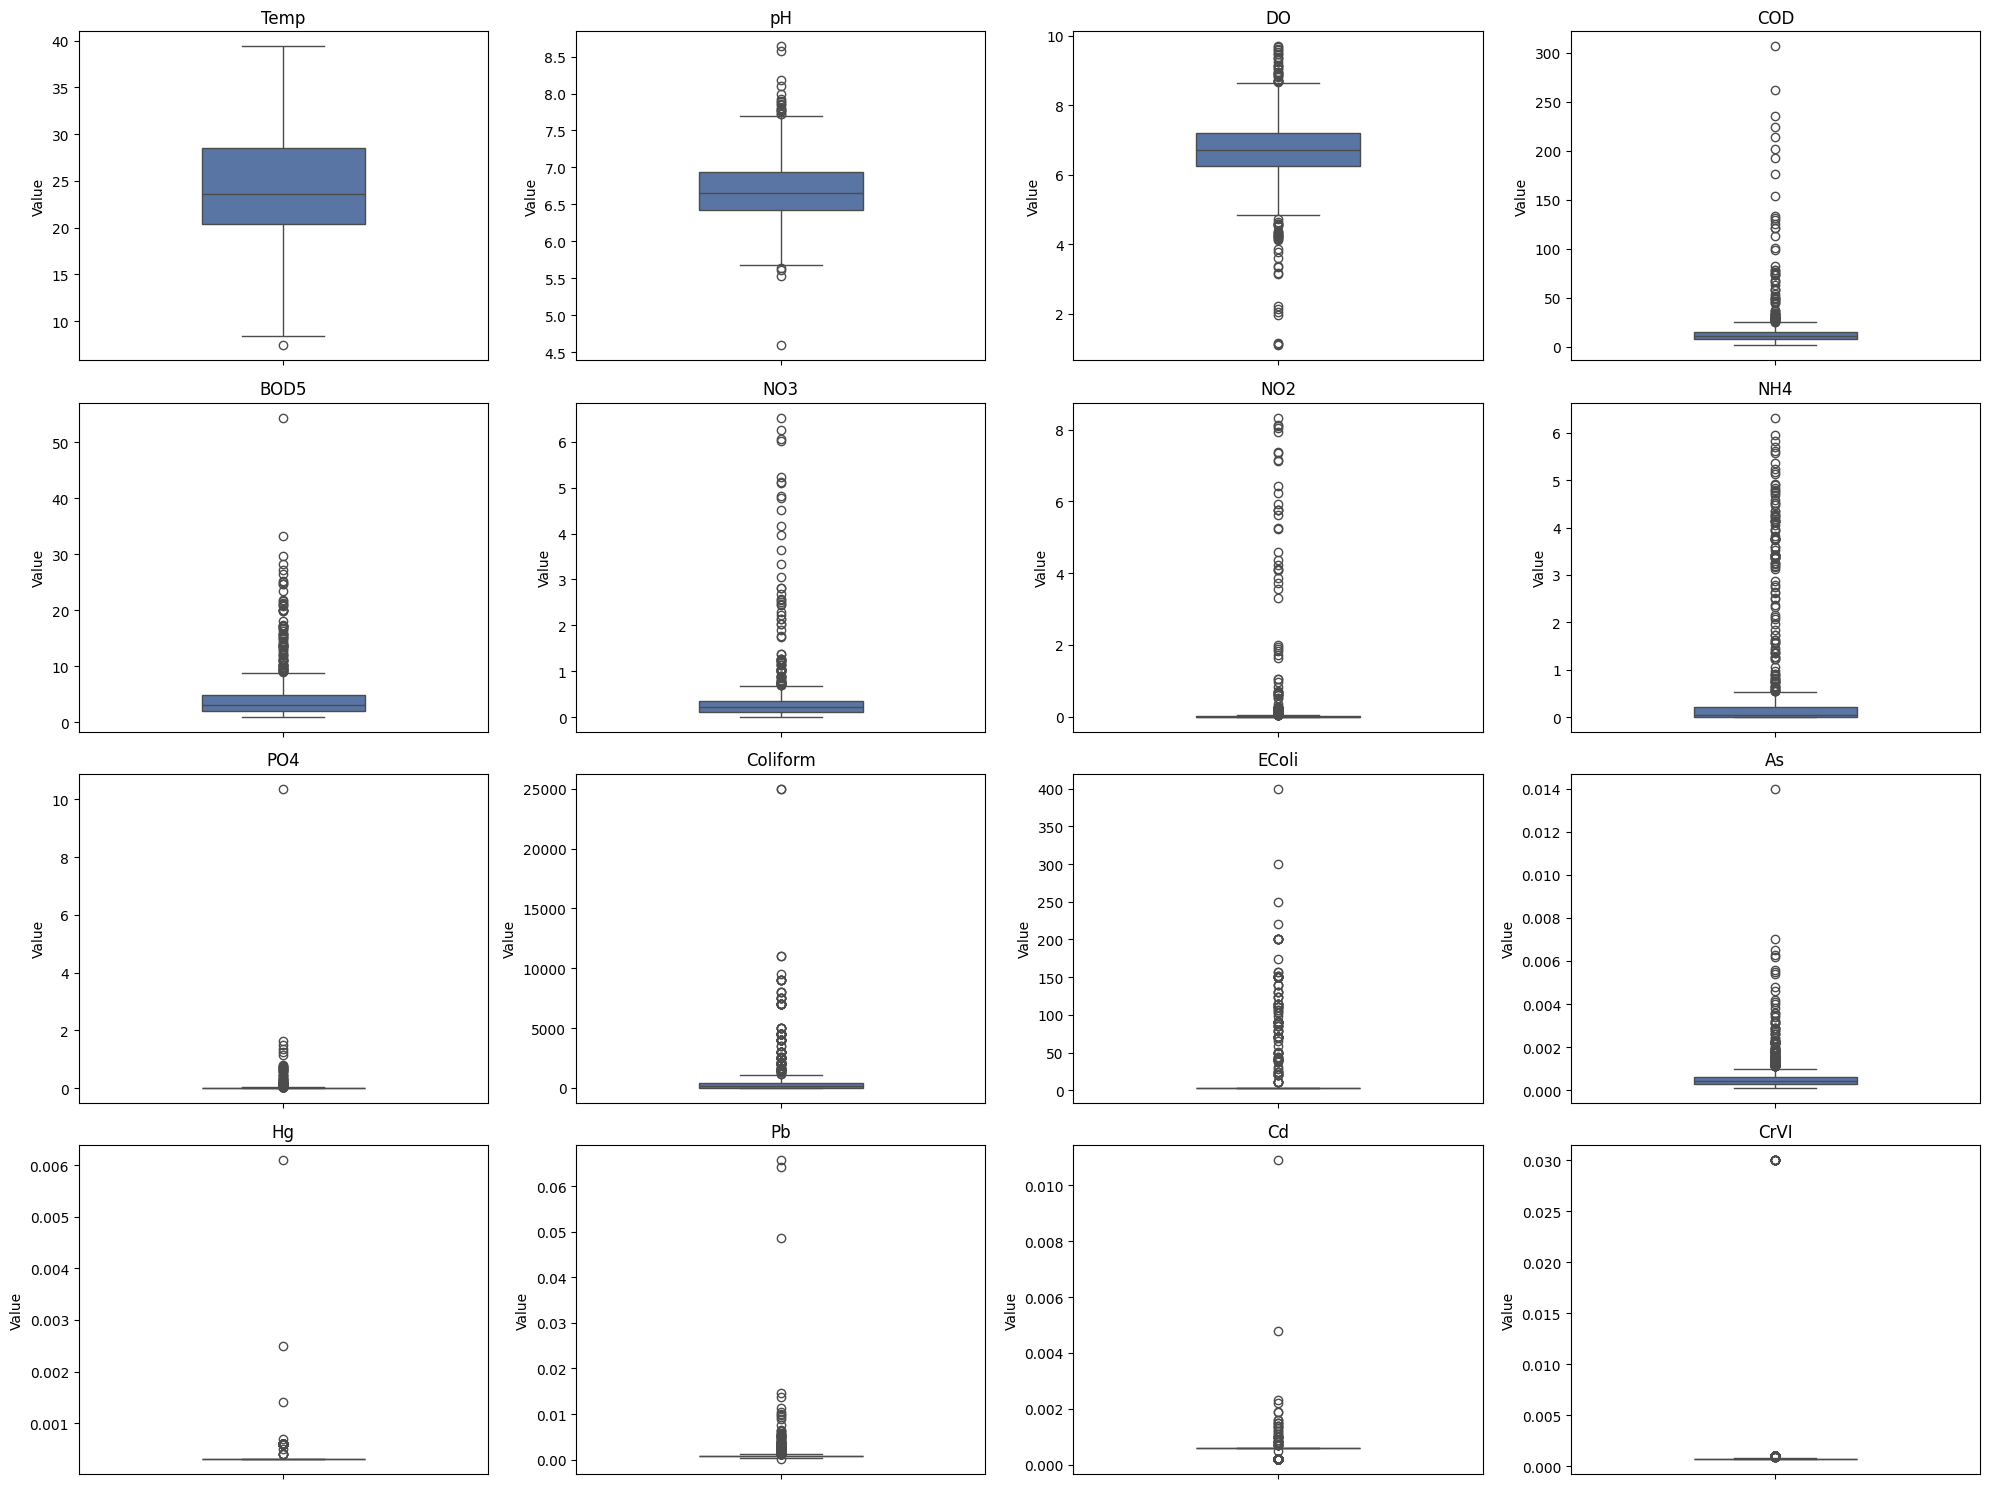

In [86]:
numeric_cols = full_data.select_dtypes(include='number').columns
n_numeric_cols = len(numeric_cols)

nrows = 4
ncols = 4

plt.figure(figsize=(20, 15)) # Adjusted figure size for a 3x5 grid

for i, col_name in enumerate(numeric_cols[:nrows * ncols]): # Iterate through the first 15 columns
    ax = plt.subplot(nrows, ncols, i + 1)
    sns.boxplot(
        y=full_data[col_name],
        ax=ax,
        color="#4c72b0",
        width=0.4
    )
    ax.set_title(col_name, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

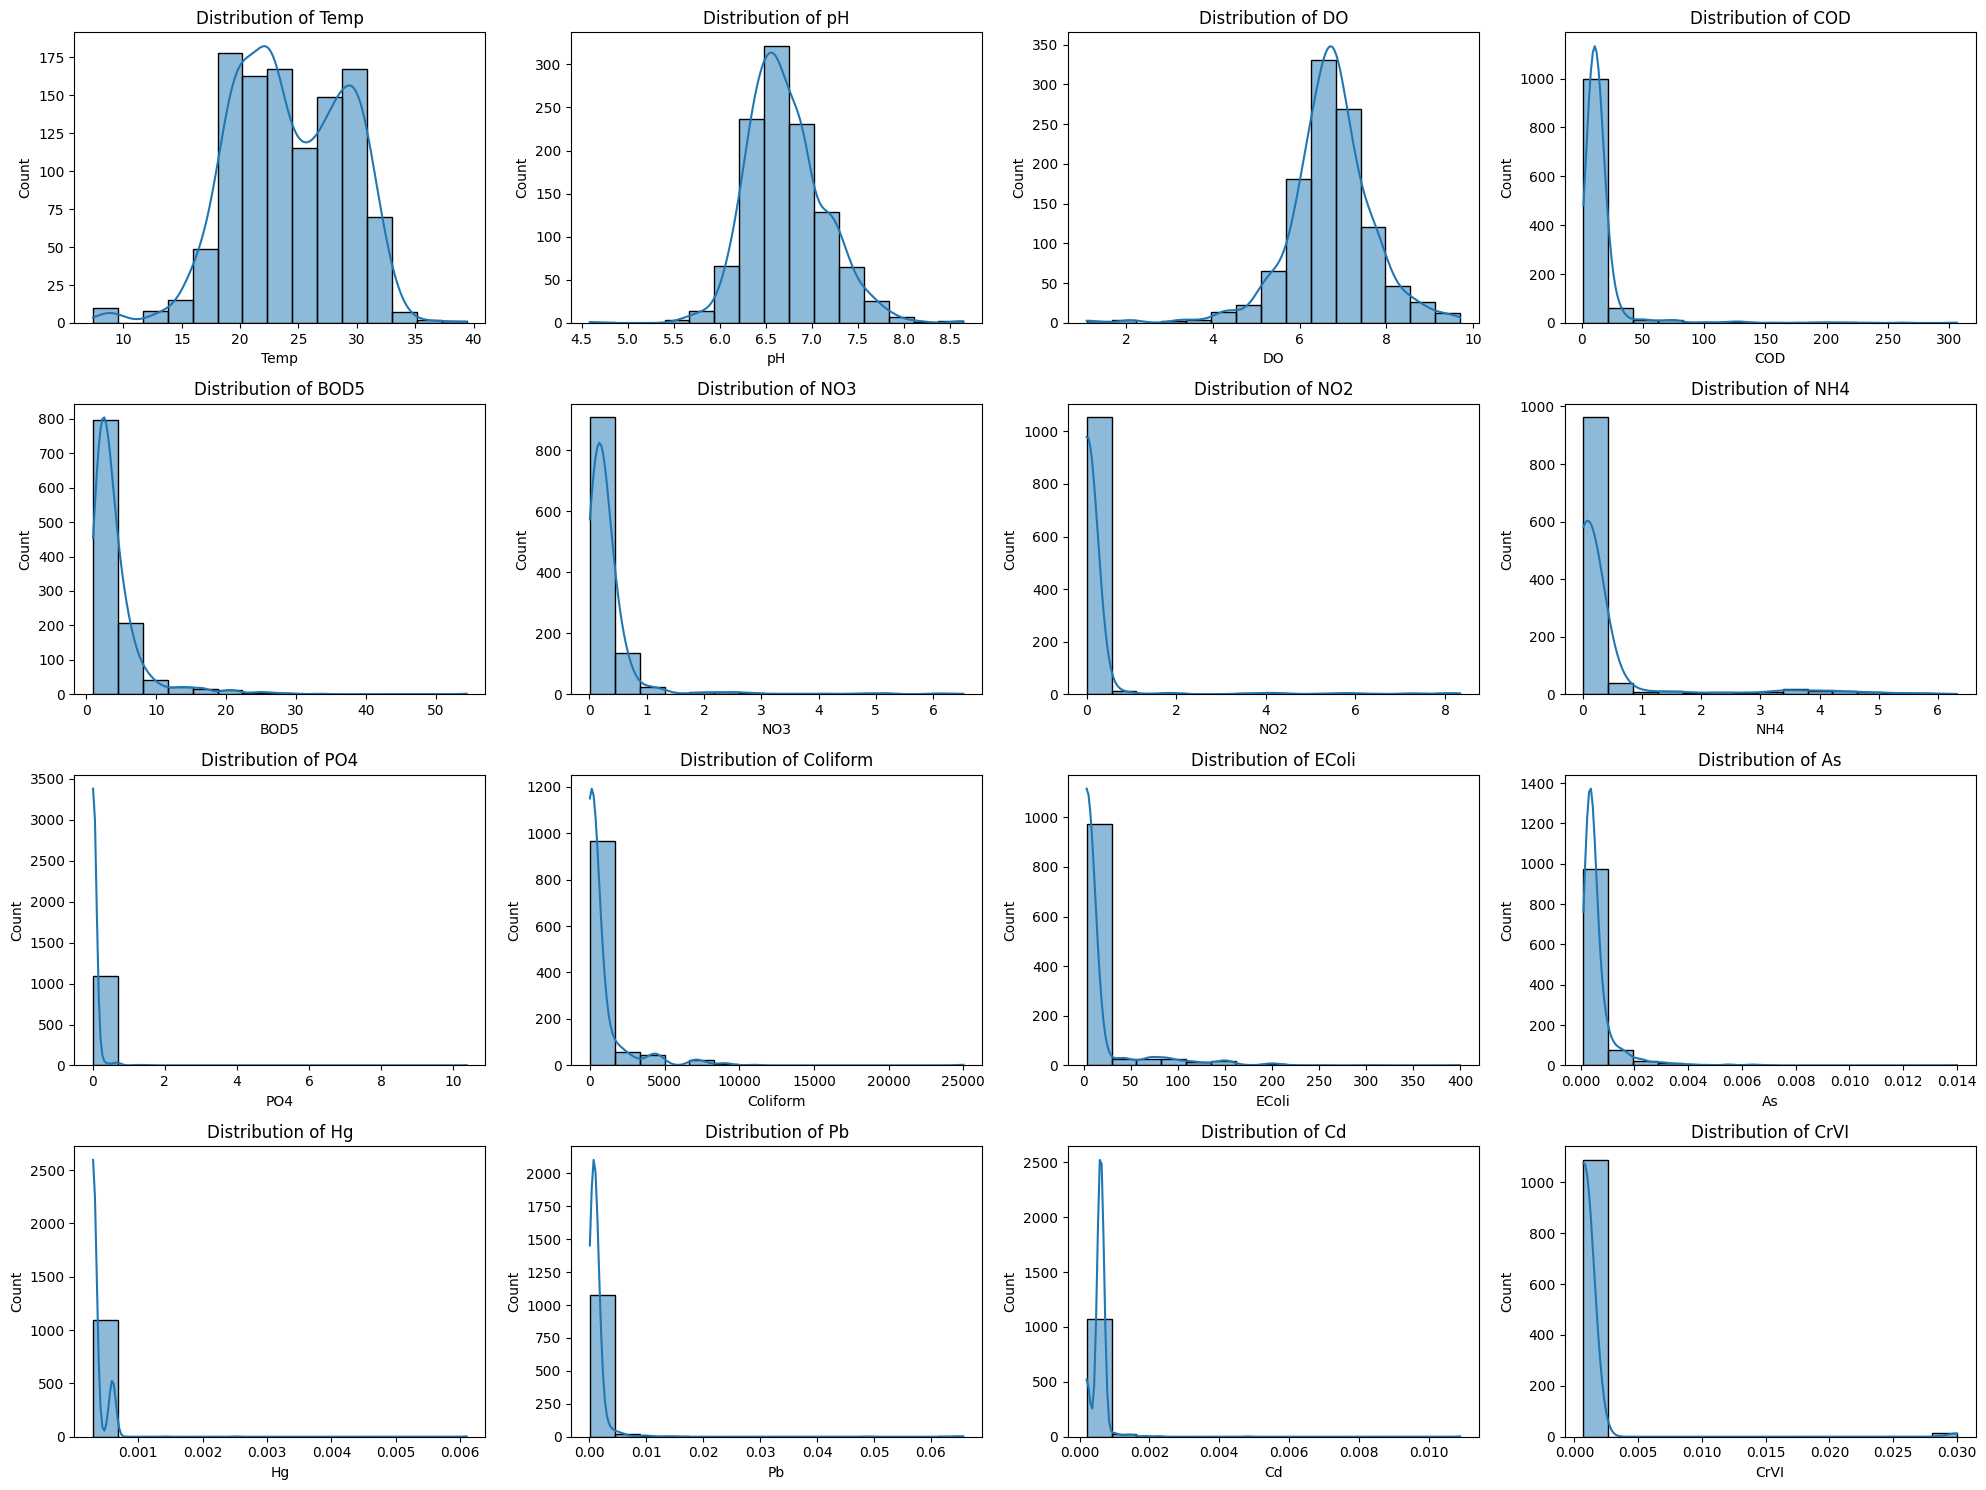

In [87]:
numeric_cols = full_data.select_dtypes(include='number').columns
n_numeric_cols = len(numeric_cols)

nrows = 4
ncols = 4

plt.figure(figsize=(20, 15)) # Adjusted figure size for a 3x5 grid

for i, col_name in enumerate(numeric_cols[:nrows * ncols]): # Iterate through the first 15 columns
    ax = plt.subplot(nrows, ncols, i + 1)
    sns.histplot(
        data=full_data,
        x=col_name,
        bins=15,
        kde=True,
        ax=ax
    )
    ax.set_title(f'Distribution of {col_name}', fontsize=12)
    ax.set_xlabel(col_name)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

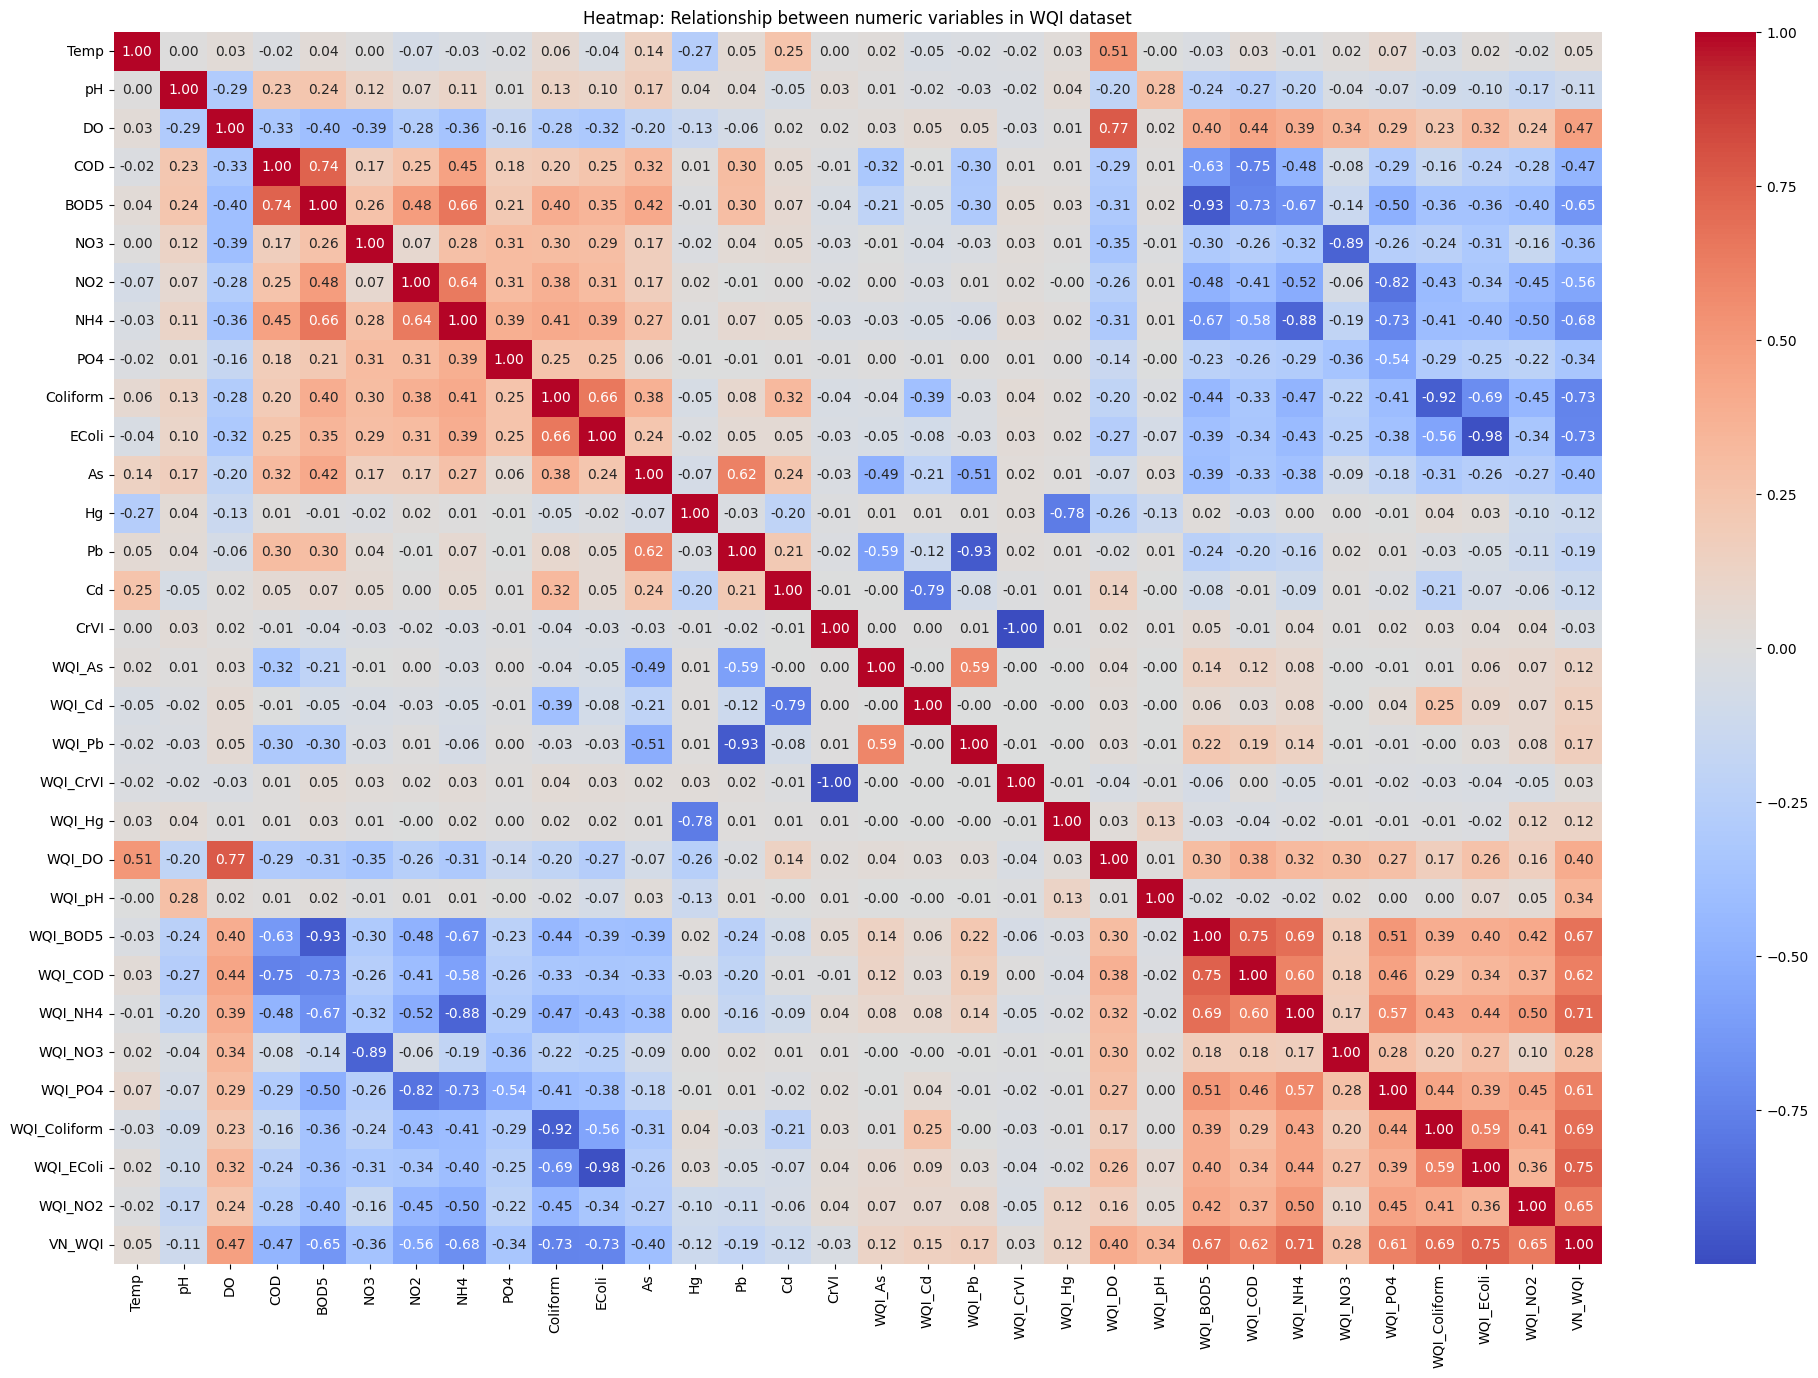

In [88]:
# Get numeric columns
numeric_cols = full_data.select_dtypes(include=['int64', 'float64']).columns
df_numeric = full_data[numeric_cols]

# Calculate correlation matrix
corr_matrix = df_numeric.corr()

plt.figure(figsize=(24, 16))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Relationship between numeric variables in WQI dataset")
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_8120\2833595069.py:6: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



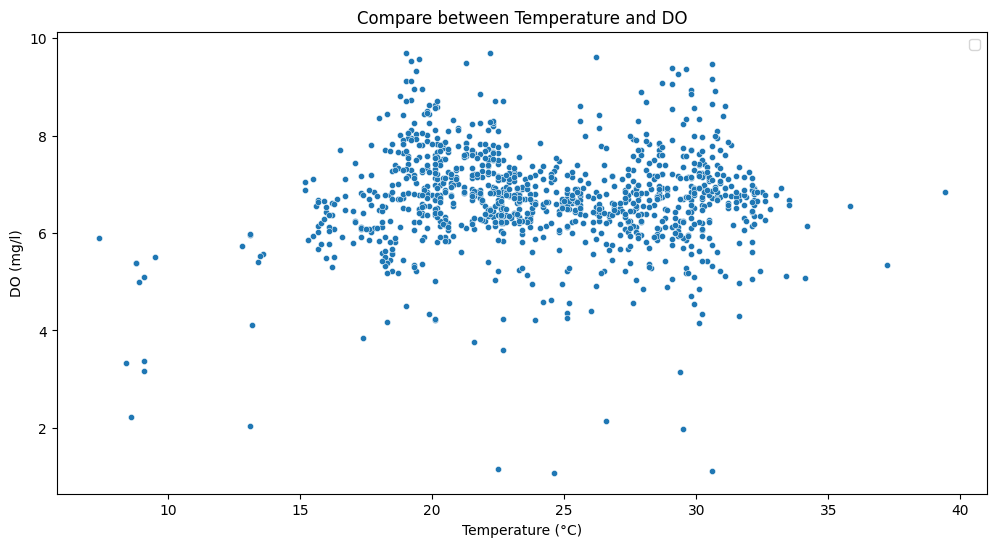

In [89]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=full_data, x='Temp', y='DO',s=20)
plt.title('Compare between Temperature and DO')
plt.xlabel('Temperature (°C)')
plt.ylabel('DO (mg/l)')
plt.legend()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_8120\1813118795.py:6: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



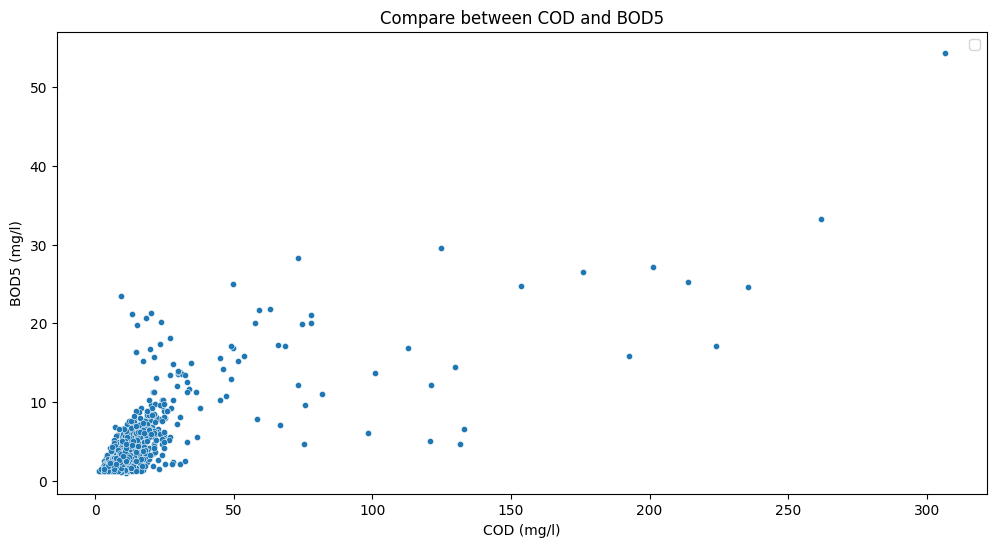

In [90]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=full_data, x='COD', y='BOD5',s=20)
plt.title('Compare between COD and BOD5')
plt.xlabel('COD (mg/l)')
plt.ylabel('BOD5 (mg/l)')
plt.legend()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_8120\3408095388.py:6: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



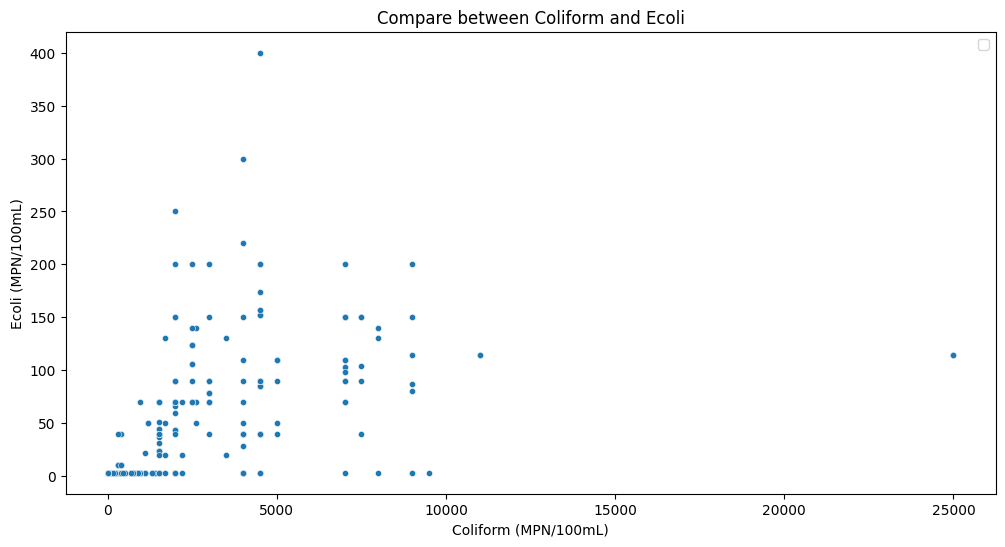

In [91]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=full_data, x='Coliform', y='EColi',s=20)
plt.title('Compare between Coliform and Ecoli')
plt.xlabel('Coliform (MPN/100mL)')
plt.ylabel('Ecoli (MPN/100mL)')
plt.legend()
plt.show()

# 3. Feature Engineering


---

In [31]:
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LinearRegression())
])

knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

svr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

Standard scaling is applied for Linear Regression and K-Nearest Neighbors because these models are sensitive to the scale of features. On the other hand, Random Forest and Gradient Boosting do not require feature scaling, as they are tree-based models and are insensitive to the magnitude of the features.

# 4. Direct Measurement Inputs

## 4.1 Before applying feature selection

### 4.1.1. Classifier Training

#### Data Splitting

In [32]:
X_train = df_KNNfilled[['Temp', 'pH', 'DO', 'COD', 'BOD5',
                'NO3', 'NO2', 'NH4', 'PO4',
                'Coliform', 'EColi', 'As', 'Hg', 'Pb',
                'Cd', 'CrVI']]
X_test = test_data[['Temp', 'pH', 'DO', 'COD', 'BOD5',
                'NO3', 'NO2', 'NH4', 'PO4',
                'Coliform', 'EColi', 'As', 'Hg', 'Pb',
                'Cd', 'CrVI']]

y_train = df_KNNfilled['VN_WQI']
y_test = test_data['VN_WQI']

#### Model Training

In [33]:
def tune_random_forest(X_train, y_train, X_test, y_test, random_state=42):
    rf_param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 20, 40],
        'min_samples_leaf': [1, 2, 5],
        'max_features': ['sqrt', 0.7, 1.0]
    }

    param_combinations = list(itertools.product(
        rf_param_grid['n_estimators'],
        rf_param_grid['max_depth'],
        rf_param_grid['min_samples_leaf'],
        rf_param_grid['max_features']
    ))

    best_rmse = float('inf')
    best_params = None

    for n_estimators, max_depth, min_samples_leaf, max_features in param_combinations:
        rf = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            random_state=random_state,
            n_jobs=-1
        )
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_test)

        rmse = np.sqrt(mean_squared_error(y_test, y_pred))

        if rmse < best_rmse:
            best_rmse = rmse
            best_params = {
                'n_estimators': n_estimators,
                'max_depth': max_depth,
                'min_samples_leaf': min_samples_leaf,
                'max_features': max_features
            }

    print("Best parameters for RandomForest (based on test set RMSE):")
    print(best_params)
    print("Best RMSE on test set:", best_rmse)

    return best_params

best_rf_params = tune_random_forest(X_train, y_train, X_test, y_test)

Best parameters for RandomForest (based on test set RMSE):
{'n_estimators': 50, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 0.7}
Best RMSE on test set: 2.0413441564107413


In [34]:
def tune_gradient_boosting(X_train, y_train, X_test, y_test, random_state=42):
    gb_param_grid = {
        'n_estimators': [50, 100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }

    param_combinations = list(itertools.product(
        gb_param_grid['n_estimators'],
        gb_param_grid['learning_rate'],
        gb_param_grid['max_depth']
    ))

    best_rmse = float('inf')
    best_params = None

    for n_estimators, learning_rate, max_depth in param_combinations:
        gb = GradientBoostingRegressor(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            random_state=random_state
        )
        gb.fit(X_train, y_train)

        y_pred = gb.predict(X_test)

        rmse = np.sqrt(mean_squared_error(y_test, y_pred))

        if rmse < best_rmse:
            best_rmse = rmse
            best_params = {
                'n_estimators': n_estimators,
                'learning_rate': learning_rate,
                'max_depth': max_depth
            }

    print("Best parameters for GradientBoosting (based on test set RMSE):")
    print(best_params)
    print("Best RMSE on test set:", best_rmse)

    return best_params

best_gb_params = tune_gradient_boosting(X_train, y_train, X_test, y_test)

Best parameters for GradientBoosting (based on test set RMSE):
{'n_estimators': 200, 'learning_rate': 0.1, 'max_depth': 3}
Best RMSE on test set: 1.4912620424041736


In [35]:
def tune_knn(knn_model, X_train, y_train, X_test, y_test):
    knn_param_grid = {
        'n_neighbors': [3, 5, 6, 7, 9],
        'weights': ['uniform', 'distance'],
        'metric': ['minkowski', 'euclidean', 'manhattan'],
        'p': [1, 2]
    }

    param_combinations = list(itertools.product(
        knn_param_grid['n_neighbors'],
        knn_param_grid['weights'],
        knn_param_grid['metric'],
        knn_param_grid['p']
    ))

    best_rmse = float('inf')
    best_params = None

    for n_neighbors, weights, metric, p in param_combinations:
        knn_model.set_params(
        knn__n_neighbors=n_neighbors,
        knn__weights=weights,
        knn__metric=metric,
        knn__p=p
    )

        knn_model.fit(X_train, y_train)

        y_pred = knn_model.predict(X_test)

        rmse = np.sqrt(mean_squared_error(y_test, y_pred))

        if rmse < best_rmse:
            best_rmse = rmse
            best_params = {
                'n_neighbors': n_neighbors,
                'weights': weights,
                'metric': metric,
                'p': p
            }

    print("Best parameters for KNN (based on test set RMSE):")
    print(best_params)
    print("Best RMSE on test set:", best_rmse)

    return best_params

best_knn_params = tune_knn(knn_model, X_train, y_train, X_test, y_test)

Best parameters for KNN (based on test set RMSE):
{'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 1}
Best RMSE on test set: 3.6546995095254386


In [36]:
def tune_svr(svr_model, X_train, y_train, X_test, y_test):
    param_grid = {
        'C': [0.1, 1, 10, 100],
        'epsilon': [0.01, 0.1, 0.2, 0.5],
        'gamma': ['scale', 'auto', 0.01, 0.1, 1]
    }

    param_combinations = list(itertools.product(
        param_grid['C'],
        param_grid['epsilon'],
        param_grid['gamma']
    ))

    best_rmse = float('inf')
    best_params = None

    for C, epsilon, gamma in param_combinations:
        svr_model.set_params(
        svr__C=C,
        svr__epsilon=epsilon,
        svr__gamma=gamma
    )

        svr_model.fit(X_train, y_train)

        y_pred = svr_model.predict(X_test)

        rmse = np.sqrt(mean_squared_error(y_test, y_pred))

        if rmse < best_rmse:
            best_rmse = rmse
            best_params = {
                'C': C,
                'epsilon': epsilon,
                'gamma': gamma
            }

    print("Best parameters for SVR (based on test set RMSE):")
    print(best_params)
    print("Best RMSE on test set:", best_rmse)

    return best_params

best_svr_params = tune_svr(svr_model, X_train, y_train, X_test, y_test)

Best parameters for SVR (based on test set RMSE):
{'C': 100, 'epsilon': 0.5, 'gamma': 'scale'}
Best RMSE on test set: 2.788090304668205


In [37]:
def train_all_models(X_train, y_train, X_test,
                     best_rf_params, best_gb_params,
                     lr_model, knn_model, best_knn_params,
                     svr_model, best_svr_params):

    models = {}
    predictions = {}

    # Random Forest
    rf_model = RandomForestRegressor(**best_rf_params, random_state=42)
    rf_model.fit(X_train, y_train)
    models['RF'] = rf_model
    predictions['RF'] = rf_model.predict(X_test)

    # Gradient Boosting
    gb_model = GradientBoostingRegressor(**best_gb_params, random_state=42)
    gb_model.fit(X_train, y_train)
    models['GB'] = gb_model
    predictions['GB'] = gb_model.predict(X_test)

    # Linear Regression (Bagging)
    lr_bagging = BaggingRegressor(estimator=lr_model, n_estimators=200, random_state=42)
    lr_bagging.fit(X_train, y_train)
    models['LR'] = lr_bagging
    predictions['LR'] = lr_bagging.predict(X_test)

    # KNN (Pipeline)
    knn_model.set_params(
        knn__n_neighbors=best_knn_params['n_neighbors'],
        knn__weights=best_knn_params['weights'],
        knn__metric=best_knn_params['metric'],
        knn__p=best_knn_params['p']
    )
    knn_model.fit(X_train, y_train)
    models['KNN'] = knn_model
    predictions['KNN'] = knn_model.predict(X_test)

    # SVR (Pipeline + Bagging)
    svr_model.set_params(
        svr__C=best_svr_params['C'],
        svr__epsilon=best_svr_params['epsilon'],
        svr__gamma=best_svr_params['gamma']
    )
    svr_bagging = BaggingRegressor(estimator=svr_model, n_estimators=200, random_state=42)
    svr_bagging.fit(X_train, y_train)
    models['SVR'] = svr_bagging
    predictions['SVR'] = svr_bagging.predict(X_test)

    return models, predictions


# Sử dụng
models, predictions = train_all_models(
    X_train, y_train, X_test,
    best_rf_params, best_gb_params,
    lr_model, knn_model, best_knn_params,
    svr_model, best_svr_params
)

# Lấy dự đoán
rf_pred = predictions['RF']
gb_pred = predictions['GB']
lr_pred = predictions['LR']
knn_pred = predictions['KNN']
svr_pred = predictions['SVR']

In [38]:
def evaluate_stacking(best_rf_params, knn_model, best_knn_params, lr_model, svr_model, best_svr_params, best_gb_params,
                      X_train, y_train, X_test, y_test, meta_model=None):

    rf_model = RandomForestRegressor(**best_rf_params, random_state=42)
    gb_model = GradientBoostingRegressor(**best_gb_params, random_state=42)
    lr_bagging = BaggingRegressor(estimator=lr_model, n_estimators=200, random_state=42)

    # Sửa KeyError bằng cách thêm prefix step__ khi set params cho Pipeline
    knn_model.set_params(
        knn__n_neighbors=best_knn_params['n_neighbors'],
        knn__weights=best_knn_params['weights'],
        knn__metric=best_knn_params['metric'],
        knn__p=best_knn_params['p']
    )

    svr_model.set_params(
        svr__C=best_svr_params['C'],
        svr__epsilon=best_svr_params['epsilon'],
        svr__gamma=best_svr_params['gamma']
    )
    svr_bagging = BaggingRegressor(estimator=svr_model, n_estimators=200, random_state=42)

    if meta_model is None:
        from sklearn.linear_model import LinearRegression
        meta_model = LinearRegression()

    models = {
        'RF': rf_model,
        'KNN': knn_model,
        'LR': lr_bagging,
        'SVR': svr_bagging,
        'GB': gb_model
    }

    import itertools
    import pandas as pd
    from sklearn.ensemble import StackingRegressor
    from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

    results = []
    model_names = list(models.keys())
    best_stacking_model = None
    best_rmse = float('inf')

    for r in range(2, len(model_names) + 1):
        for combo in itertools.combinations(model_names, r):
            estimators = [(name.lower(), models[name]) for name in combo]

            stacking = StackingRegressor(
                estimators=estimators,
                final_estimator=meta_model,
                n_jobs=-1
            )

            stacking.fit(X_train, y_train)
            preds = stacking.predict(X_test)

            mse = mean_squared_error(y_test, preds)
            rmse = np.sqrt(mse)
            mae = mean_absolute_error(y_test, preds)
            r2 = r2_score(y_test, preds)

            results.append({
                'Base Models': " + ".join(combo),
                'Num Models': len(combo),
                'MSE': mse,
                'RMSE': rmse,
                'MAE': mae,
                'R2': r2
            })

            if rmse < best_rmse:
                best_rmse = rmse
                best_stacking_model = stacking

    results_df = pd.DataFrame(results).sort_values(by='RMSE')
    return results_df, best_stacking_model

results_df, best_stacking_model = evaluate_stacking(
    best_rf_params=best_rf_params,
    knn_model=knn_model,
    best_knn_params=best_knn_params,
    lr_model=lr_model,
    svr_model=svr_model,
    best_svr_params=best_svr_params,
    best_gb_params=best_gb_params,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test
)

#### Model Evaluation

In [39]:
def evaluate_models(y_test, predictions_dict, decimal_places=4):
    """
    Evaluate multiple models and display results in a formatted table.

    Parameters:
    -----------
    y_test : array-like
        True target values
    predictions_dict : dict
        Dictionary with model names as keys and predictions as values
        Example: {'Random Forest': rf_pred, 'Linear Regression': lr_pred}
    decimal_places : int, default=4
        Number of decimal places to round the results

    Returns:
    --------
    pd.DataFrame
        DataFrame containing all evaluation metrics for each model
    """
    results = {
        'Model': [],
        'MSE': [],
        'RMSE': [],
        'MAE': [],
        'R²': []
    }

    for model_name, predictions in predictions_dict.items():
        results['Model'].append(model_name)
        results['MSE'].append(mean_squared_error(y_test, predictions))
        results['RMSE'].append(np.sqrt(mean_squared_error(y_test, predictions)))
        results['MAE'].append(mean_absolute_error(y_test, predictions))
        results['R²'].append(r2_score(y_test, predictions))

    comparison_df = pd.DataFrame(results)
    comparison_df = comparison_df.round(decimal_places)
    print(comparison_df.to_string(index=False))

    return comparison_df

# Use the function to evaluate all models
predictions_dict = {
    'Random Forest': rf_pred,
    'Gradient Boosting': gb_pred,
    'Linear Regression': lr_pred,
    'K-Nearest Neighbors': knn_pred,
    'Support Vector Regression': svr_pred
}

comparison_df = evaluate_models(y_test, predictions_dict, decimal_places=4)

                    Model     MSE   RMSE    MAE     R²
            Random Forest  4.1671 2.0413 0.8824 0.9685
        Gradient Boosting  2.2239 1.4913 0.7387 0.9832
        Linear Regression 14.5537 3.8149 2.1750 0.8899
      K-Nearest Neighbors 13.3568 3.6547 1.7518 0.8990
Support Vector Regression 10.9654 3.3114 1.5597 0.9170


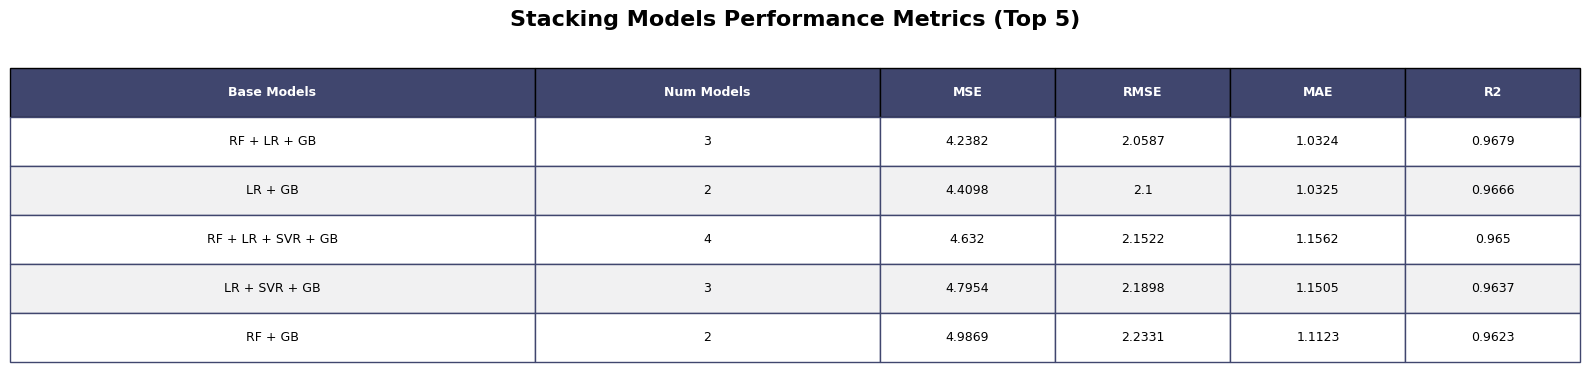

In [40]:
def plot_results_table(
    results_df,
    title="Stacking Models Performance Metrics",
    figsize_width=16,
    row_height=0.35,
    font_size=9,
    header_color="#40466e",
    alt_row_color="#f1f1f2",
    top_n=5
):
    top_results = results_df.nsmallest(top_n, 'RMSE')

    fig, ax = plt.subplots(
        figsize=(figsize_width, len(top_results) * row_height + 2)
    )
    ax.axis('off')

    tbl = ax.table(
        cellText=top_results.round(4).values,
        colLabels=top_results.columns,
        cellLoc='center',
        loc='center',
        bbox=[0, 0, 1, 0.95]
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(font_size)
    tbl.auto_set_column_width(col=list(range(len(top_results.columns))))

    for (i, j), cell in tbl.get_celld().items():
        cell.set_height(0.06)
        if i == 0:
            cell.set_facecolor(header_color)
            cell.set_text_props(weight='bold', color='white')
        else:
            cell.set_facecolor(alt_row_color if i % 2 == 0 else 'white')
            cell.set_edgecolor(header_color)

    fig.suptitle(f'{title} (Top {top_n})', fontsize=16, weight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

plot_results_table(results_df, top_n=5)

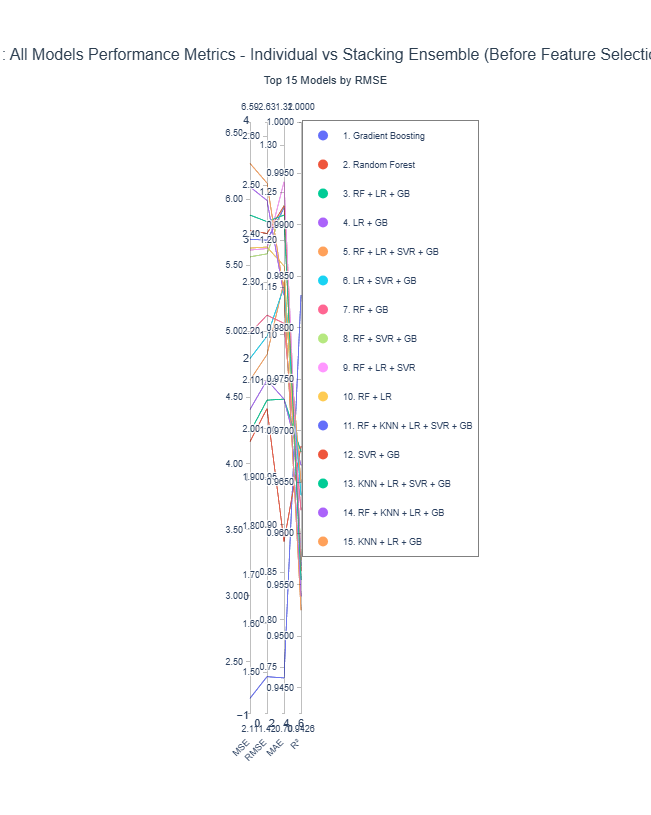

In [41]:
def plot_parallel_coordinates_all_models(
    results_df,
    y_test,
    rf_pred,
    gb_pred,
    lr_pred,
    knn_pred,
    svr_pred,
    title="All Models Performance Metrics",
    top_n=15
):
    df_plot = results_df.copy()

    individual_predictions = {
        'Random Forest': rf_pred,
        'Gradient Boosting': gb_pred,
        'Linear Regression': lr_pred,
        'K-Nearest Neighbors': knn_pred,
        'Support Vector Regression': svr_pred
    }

    individual_rows = []
    for model_name, predictions in individual_predictions.items():
        mse = mean_squared_error(y_test, predictions)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test, predictions)
        r2 = r2_score(y_test, predictions)

        individual_rows.append({
            'Base Models': model_name,
            'Num Models': 1,
            'MSE': mse,
            'RMSE': rmse,
            'MAE': mae,
            'R2': r2
        })

    df_individual = pd.DataFrame(individual_rows)
    df_plot = pd.concat([df_individual, df_plot], ignore_index=True)
    df_plot = df_plot.nsmallest(top_n, 'RMSE').reset_index(drop=True)

    import plotly.express as px
    colors = px.colors.qualitative.Plotly
    n_models = len(df_plot)
    color_mapping = [colors[i % len(colors)] for i in range(n_models)]

    fig = go.Figure(data=
        go.Parcoords(
            line=dict(
                color=list(range(n_models)),
                colorscale=[[i/(n_models-1), color_mapping[i]] for i in range(n_models)],
                showscale=False
            ),
            dimensions=[
                dict(
                    range=[df_plot['MSE'].min() * 0.95, df_plot['MSE'].max() * 1.05],
                    label='MSE',
                    values=df_plot['MSE'].tolist(),
                    tickformat='.2f'
                ),
                dict(
                    range=[df_plot['RMSE'].min() * 0.95, df_plot['RMSE'].max() * 1.05],
                    label='RMSE',
                    values=df_plot['RMSE'].tolist(),
                    tickformat='.2f'
                ),
                dict(
                    range=[df_plot['MAE'].min() * 0.95, df_plot['MAE'].max() * 1.05],
                    label='MAE',
                    values=df_plot['MAE'].tolist(),
                    tickformat='.2f'
                ),
                dict(
                    range=[df_plot['R2'].min() - 0.01, 1.0],
                    label='R²',
                    values=df_plot['R2'].tolist(),
                    tickformat='.4f'
                )
            ],
            labelangle=-45,
            labelside='bottom'
        )
    )

    fig.update_layout(
        title=dict(
            text=f"{title}<br><sub>Top {top_n} Models by RMSE</sub>",
            font=dict(size=16, family='Arial, sans-serif', color='#2c3e50'),
            x=0.5,
            xanchor='center'
        ),
        plot_bgcolor='white',
        paper_bgcolor='white',
        font=dict(size=11, family='Arial, sans-serif'),
        height=800,
        width=1400,
        margin=dict(l=250, r=350, t=120, b=100),
        hovermode='closest',
        showlegend=True,
        legend=dict(
            orientation="v",
            yanchor="top",
            y=1.0,
            xanchor="left",
            x=1.02,
            bgcolor="rgba(255, 255, 255, 0.95)",
            bordercolor="gray",
            borderwidth=1,
            font=dict(size=9)
        ),
        xaxis=dict(showgrid=False),
        yaxis=dict(showgrid=False)
    )

    for i, row in df_plot.iterrows():
        fig.add_trace(go.Scatter(
            x=[None], y=[None],
            mode='markers',
            marker=dict(size=10, color=color_mapping[i]),
            legendgroup=row['Base Models'],
            showlegend=True,
            name=f"{i+1}. {row['Base Models'][:30]}",
            hovertemplate=f"<b>{row['Base Models']}</b><br>" +
                         f"Num Models: {int(row['Num Models'])}<br>" +
                         f"MSE: {row['MSE']:.4f}<br>" +
                         f"RMSE: {row['RMSE']:.4f}<br>" +
                         f"MAE: {row['MAE']:.4f}<br>" +
                         f"R²: {row['R2']:.4f}<br>" +
                         "<extra></extra>"
        ))

    return fig

fig_all_models_41 = plot_parallel_coordinates_all_models(
    results_df=results_df,
    y_test=y_test,
    rf_pred=rf_pred,
    gb_pred=gb_pred,
    lr_pred=lr_pred,
    knn_pred=knn_pred,
    svr_pred=svr_pred,
    title="4.1: All Models Performance Metrics - Individual vs Stacking Ensemble (Before Feature Selection)",
    top_n=15
)

fig_all_models_41.show()

### 4.1.2. Feature Importance

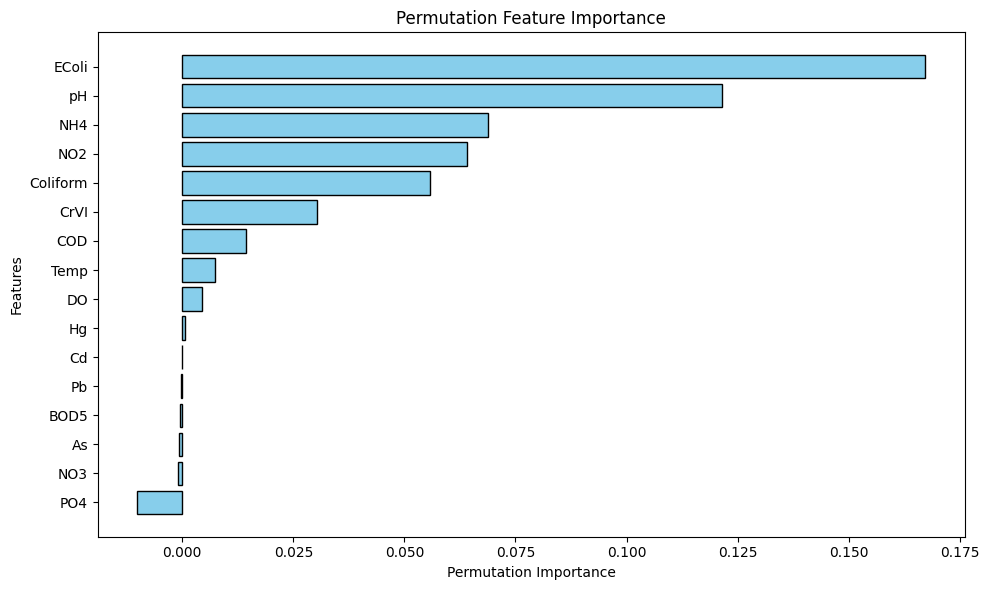

In [42]:
def plot_permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42, figsize=(10,6), color="skyblue"):
    """
    Calculate and plot permutation importance for a given model and test data.

    Parameters:
    - model: Trained model to evaluate
    - X_test: Test features (DataFrame)
    - y_test: Test labels
    - n_repeats: Number of permutation rounds (default=30)
    - random_state: Random seed for reproducibility (default=42)
    - figsize: Tuple for figure size (default=(10,6))
    - color: Bar color for the plot (default="skyblue")
    """
    # Calculate permutation importance
    perm_importance = permutation_importance(model, X_test, y_test, n_repeats=n_repeats, random_state=random_state)

    # Sort features by importance
    sorted_idx = perm_importance.importances_mean.argsort()

    # Plot
    plt.figure(figsize=figsize)
    plt.barh(
        X_test.columns[sorted_idx],
        perm_importance.importances_mean[sorted_idx],
        color=color,
        edgecolor="black"
    )
    plt.xlabel("Permutation Importance")
    plt.ylabel("Features")
    plt.title("Permutation Feature Importance")
    plt.tight_layout()
    plt.show()

    # Return permutation importance object if needed
    return perm_importance

perm_importance_result = plot_permutation_importance(best_stacking_model, X_test, y_test)

## 4.2. After applying feature selection

### 4.2.1. Classifier Training

#### Data Splitting

In [43]:
X_train_retrain = df_KNNfilled[['Temp', 'pH', 'DO', 'COD',
                'NO2', 'PO4',
                'EColi',  'Hg', 'Pb', 'CrVI']]
X_test_retrain = test_data[['Temp', 'pH', 'DO', 'COD',
                'NO2', 'PO4',
                'EColi',  'Hg', 'Pb', 'CrVI']]

y_train_retrain = df_KNNfilled['VN_WQI']
y_test_retrain = test_data['VN_WQI']

#### Model Training

In [44]:
best_rf_params_retrain = tune_random_forest(X_train_retrain, y_train_retrain, X_test_retrain, y_test_retrain)
print("\n ")
best_gb_params_retrain = tune_gradient_boosting(X_train_retrain, y_train_retrain, X_test_retrain, y_test_retrain)
print("\n ")
best_knn_params_retrain = tune_knn(knn_model, X_train_retrain, y_train_retrain, X_test_retrain, y_test_retrain)
print("\n ")
best_svr_params_retrain = tune_svr(svr_model, X_train_retrain, y_train_retrain, X_test_retrain, y_test_retrain)

Best parameters for RandomForest (based on test set RMSE):
{'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Best RMSE on test set: 2.830103888128468

 
Best parameters for GradientBoosting (based on test set RMSE):
{'n_estimators': 50, 'learning_rate': 0.2, 'max_depth': 3}
Best RMSE on test set: 2.6611884772430714

 
Best parameters for KNN (based on test set RMSE):
{'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 1}
Best RMSE on test set: 4.363410510712468

 
Best parameters for SVR (based on test set RMSE):
{'C': 100, 'epsilon': 0.5, 'gamma': 0.01}
Best RMSE on test set: 3.97198425877025


In [45]:
models_retrain, predictions_retrain = train_all_models(
    X_train_retrain, y_train_retrain, X_test_retrain,
    best_rf_params_retrain, best_gb_params_retrain,
    lr_model, knn_model, best_knn_params_retrain,
    svr_model, best_svr_params_retrain
)

rf_pred_retrain = predictions_retrain['RF']
gb_pred_retrain = predictions_retrain['GB']
lr_pred_retrain = predictions_retrain['LR']
knn_pred_retrain = predictions_retrain['KNN']
svr_pred_retrain = predictions_retrain['SVR']

In [46]:
results_df_retrain, best_stacking_model_retrain = evaluate_stacking(
    best_rf_params=best_rf_params_retrain,
    knn_model=knn_model,
    best_knn_params=best_knn_params_retrain,
    lr_model=lr_model,
    svr_model=svr_model,
    best_svr_params=best_svr_params_retrain,
    best_gb_params=best_gb_params_retrain,
    X_train=X_train_retrain,
    y_train=y_train_retrain,
    X_test=X_test_retrain,
    y_test=y_test_retrain
)
sm_pred_retrain = best_stacking_model_retrain.predict(X_test_retrain)

### Model Evaluation

In [47]:
# Evaluate all models using the function
predictions_dict_retrain = {
    'Random Forest': rf_pred_retrain,
    'Gradient Boosting': gb_pred_retrain,
    'Linear Regression': lr_pred_retrain,
    'K-Nearest Neighbors': knn_pred_retrain,
    'Support Vector Regression': svr_pred_retrain
}

comparison_df_retrain = evaluate_models(y_test_retrain, predictions_dict_retrain, decimal_places=4)

                    Model     MSE   RMSE    MAE     R²
            Random Forest  8.0095 2.8301 1.4507 0.9394
        Gradient Boosting  7.0819 2.6612 1.4478 0.9464
        Linear Regression 29.6386 5.4441 3.3223 0.7758
      K-Nearest Neighbors 19.0394 4.3634 2.1393 0.8560
Support Vector Regression 15.7244 3.9654 1.8984 0.8810


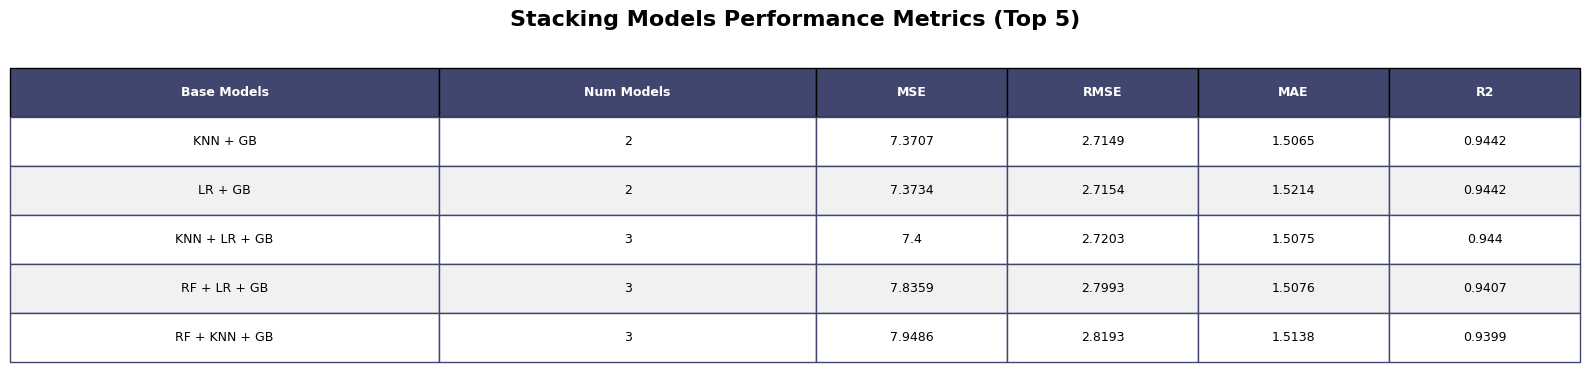

In [48]:
plot_results_table(results_df_retrain)

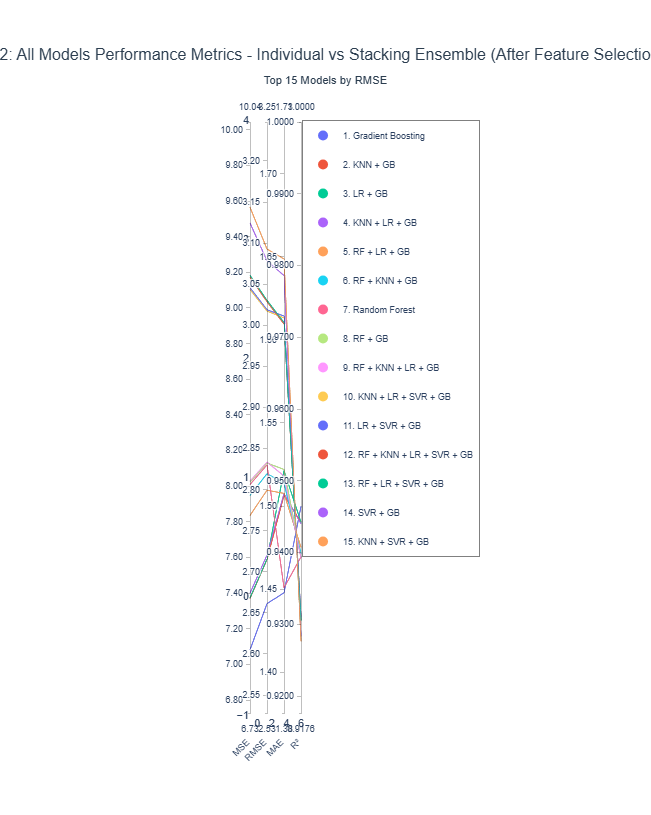

In [49]:
fig_all_models_42 = plot_parallel_coordinates_all_models(
    results_df=results_df_retrain,
    y_test=y_test_retrain,
    rf_pred=rf_pred_retrain,
    gb_pred=gb_pred_retrain,
    lr_pred=lr_pred_retrain,
    knn_pred=knn_pred_retrain,
    svr_pred=svr_pred_retrain,
    title="4.2: All Models Performance Metrics - Individual vs Stacking Ensemble (After Feature Selection)"
)

fig_all_models_42.show()

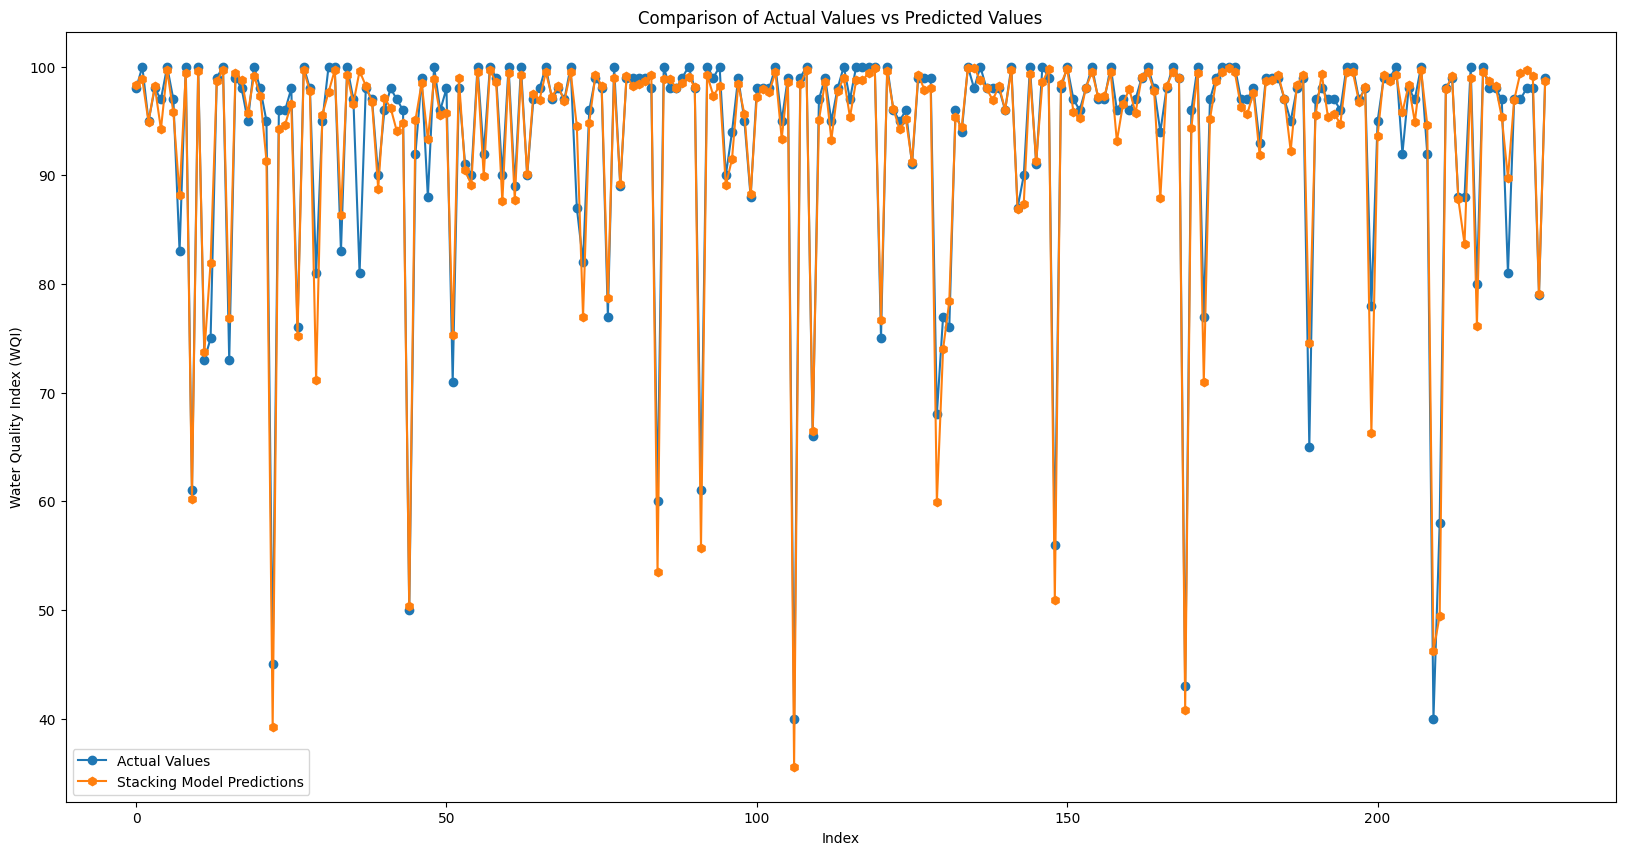

In [50]:
def plot_wqi_comparison(y_test, y_pred):
    """
    Plot a comparison between actual WQI values and predicted values.

    Parameters:
    - y_test: Actual WQI values (Pandas Series or list)
    - y_pred: Predicted WQI values (list, numpy array, or Pandas Series)

    The function does not return anything, it only displays the plot.
    """
    plt.figure(figsize=(20, 10))
    plt.plot(y_test.values, label='Actual Values', marker='o')
    plt.plot(y_pred, label='Stacking Model Predictions', marker='h')
    plt.title('Comparison of Actual Values vs Predicted Values')
    plt.xlabel('Index')
    plt.ylabel('Water Quality Index (WQI)')
    plt.legend()
    plt.show()

plot_wqi_comparison(y_test_retrain, sm_pred_retrain)

### 4.2.2. Feature Importance

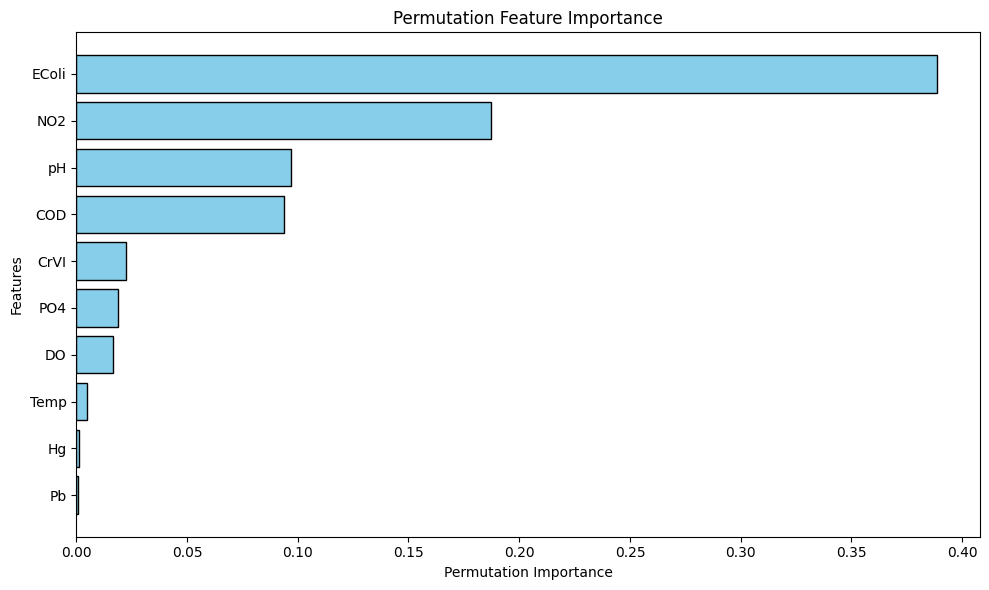

In [51]:
plot_permutation_importance(best_stacking_model_retrain, X_test_retrain, y_test_retrain);

# 5. Feature Engineered Inputs (WQI_SI)


## 5.1 Before applying feature selection


### 5.1.1. Classifier Training


#### Data Splitting

In [52]:
X_train_WQIInput = df_KNNfilled[['WQI_pH', 'WQI_DO', 'WQI_COD', 'WQI_BOD5',
                'WQI_NO3', 'WQI_NO2', 'WQI_NH4', 'WQI_PO4',
                'WQI_Coliform', 'WQI_EColi', 'WQI_As', 'WQI_Hg', 'WQI_Pb',
                'WQI_Cd', 'WQI_CrVI']]
X_test_WQIInput = test_data[['WQI_pH', 'WQI_DO', 'WQI_COD', 'WQI_BOD5',
                'WQI_NO3', 'WQI_NO2', 'WQI_NH4', 'WQI_PO4',
                'WQI_Coliform', 'WQI_EColi', 'WQI_As', 'WQI_Hg', 'WQI_Pb',
                'WQI_Cd', 'WQI_CrVI']]

y_train_WQIInput = df_KNNfilled['VN_WQI']
y_test_WQIInput = test_data['VN_WQI']

#### Model Training

In [53]:
best_rf_params_WQIInput = tune_random_forest(X_train_WQIInput, y_train_WQIInput, X_test_WQIInput, y_test_WQIInput)
print("\n ")
best_gb_params_WQIInput = tune_gradient_boosting(X_train_WQIInput, y_train_WQIInput, X_test_WQIInput, y_test_WQIInput)
print("\n ")
best_knn_params_WQIInput = tune_knn(knn_model, X_train_WQIInput, y_train_WQIInput, X_test_WQIInput, y_test_WQIInput)
print("\n ")
best_svr_params_WQIInput = tune_svr(svr_model, X_train_WQIInput, y_train_WQIInput, X_test_WQIInput, y_test_WQIInput)

Best parameters for RandomForest (based on test set RMSE):
{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Best RMSE on test set: 2.123857315175426

 
Best parameters for GradientBoosting (based on test set RMSE):
{'n_estimators': 200, 'learning_rate': 0.2, 'max_depth': 3}
Best RMSE on test set: 1.4132145651290948

 
Best parameters for KNN (based on test set RMSE):
{'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 1}
Best RMSE on test set: 1.8814749934124595

 
Best parameters for SVR (based on test set RMSE):
{'C': 100, 'epsilon': 0.1, 'gamma': 0.01}
Best RMSE on test set: 0.7409612638529095


In [54]:
models_WQIInput, predictions_WQIInput = train_all_models(
    X_train_WQIInput, y_train_WQIInput, X_test_WQIInput,
    best_rf_params_WQIInput, best_gb_params_WQIInput,
    lr_model, knn_model, best_knn_params_WQIInput,
    svr_model, best_svr_params_WQIInput
)

rf_pred_WQIInput = predictions_WQIInput['RF']
gb_pred_WQIInput = predictions_WQIInput['GB']
lr_pred_WQIInput = predictions_WQIInput['LR']
knn_pred_WQIInput = predictions_WQIInput['KNN']
svr_pred_WQIInput = predictions_WQIInput['SVR']

In [55]:
results_df_WQIInput, best_stacking_model_WQIInput = evaluate_stacking(
    best_rf_params=best_rf_params_WQIInput,
    knn_model=knn_model,
    best_knn_params=best_knn_params_WQIInput,
    lr_model=lr_model,
    svr_model=svr_model,
    best_svr_params=best_svr_params_WQIInput,
    best_gb_params=best_gb_params_WQIInput,
    X_train=X_train_WQIInput,
    y_train=y_train_WQIInput,
    X_test=X_test_WQIInput,
    y_test=y_test_WQIInput
)

#### Model Evaluation

In [56]:
# Evaluate all models using the function
predictions_dict_WQIInput = {
    'Random Forest': rf_pred_WQIInput,
    'Gradient Boosting': gb_pred_WQIInput,
    'Linear Regression': lr_pred_WQIInput,
    'K-Nearest Neighbors': knn_pred_WQIInput,
    'Support Vector Regression': svr_pred_WQIInput
}

comparison_df_WQIInput = evaluate_models(y_test_WQIInput, predictions_dict_WQIInput, decimal_places=4)

                    Model    MSE   RMSE    MAE     R²
            Random Forest 4.5108 2.1239 0.7526 0.9659
        Gradient Boosting 1.9972 1.4132 0.5942 0.9849
        Linear Regression 0.7401 0.8603 0.4293 0.9944
      K-Nearest Neighbors 3.5399 1.8815 0.6281 0.9732
Support Vector Regression 1.1575 1.0759 0.3843 0.9912


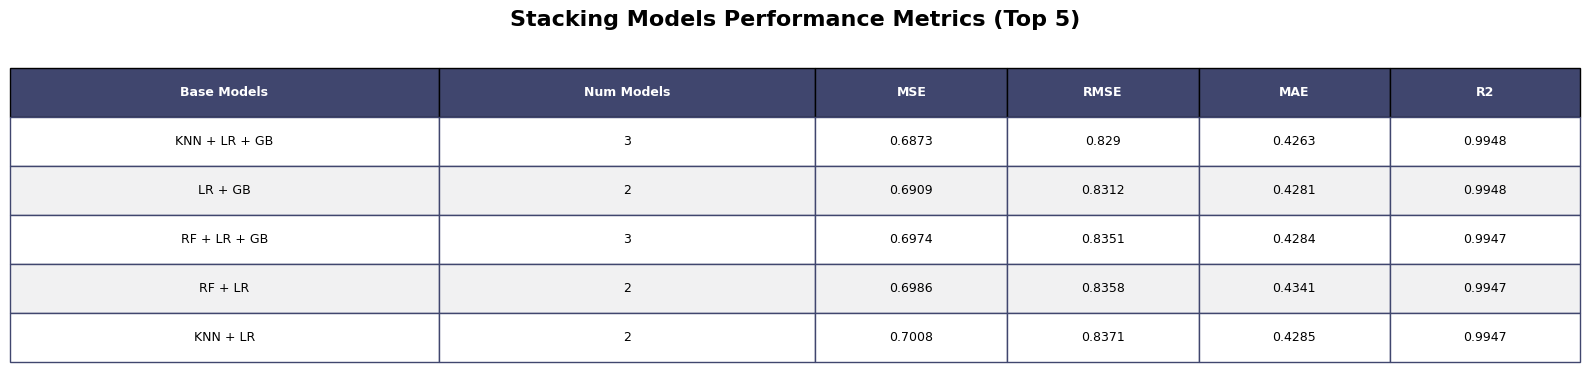

In [57]:
plot_results_table(results_df_WQIInput)

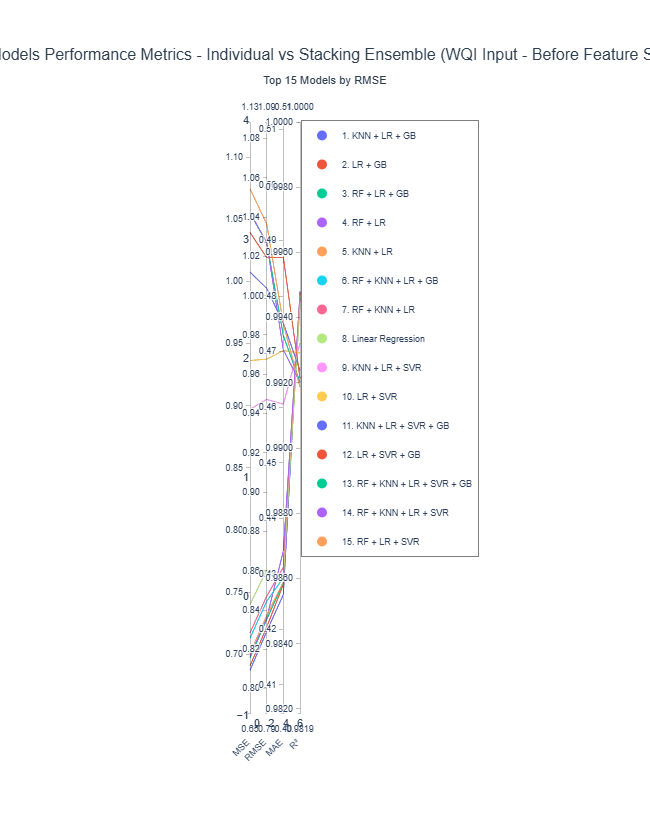

In [58]:
fig_all_models_51 = plot_parallel_coordinates_all_models(
    results_df=results_df_WQIInput,
    y_test=y_test_WQIInput,
    rf_pred=rf_pred_WQIInput,
    gb_pred=gb_pred_WQIInput,
    lr_pred=lr_pred_WQIInput,
    knn_pred=knn_pred_WQIInput,
    svr_pred=svr_pred_WQIInput,
    title="5.1: All Models Performance Metrics - Individual vs Stacking Ensemble (WQI Input - Before Feature Selection)"
)

fig_all_models_51.show()

### 5.1.2. Feature Importance

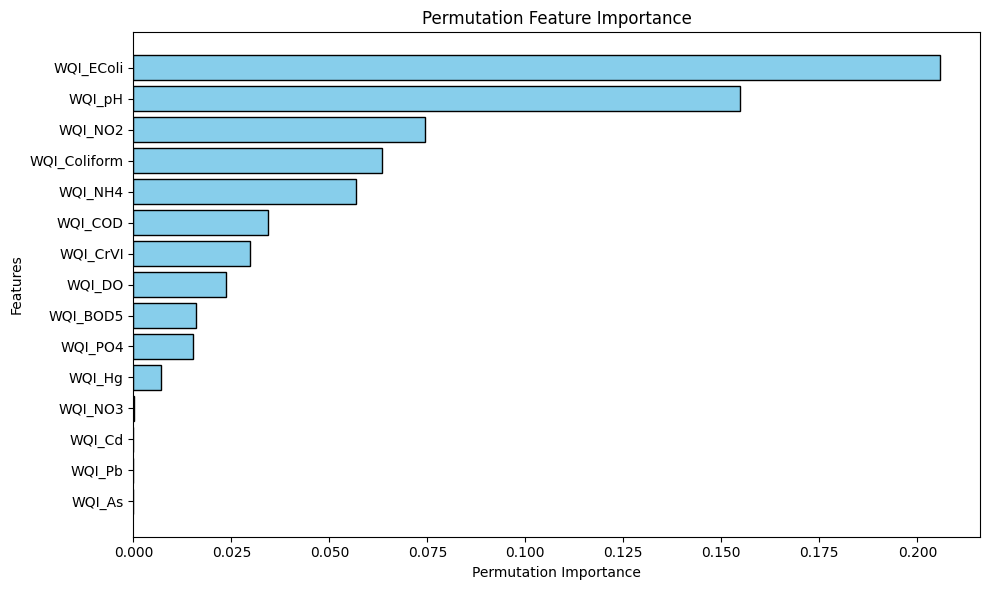

In [59]:
plot_permutation_importance(best_stacking_model_WQIInput, X_test_WQIInput, y_test_WQIInput);

## 5.2. After applying feature selection

### 5.2.1. Classifier Training

#### Data Splitting

In [60]:
X_train_WQIInput_retrain = df_KNNfilled[['WQI_pH', 'WQI_DO', 'WQI_COD',
                'WQI_NO2', 'WQI_PO4',
                'WQI_EColi', 'WQI_Hg', 'WQI_Pb',
                'WQI_CrVI']]
X_test_WQIInput_retrain = test_data[['WQI_pH', 'WQI_DO', 'WQI_COD',
                'WQI_NO2', 'WQI_PO4',
                'WQI_EColi', 'WQI_Hg', 'WQI_Pb',
                'WQI_CrVI']]

y_train_WQIInput_retrain = df_KNNfilled['VN_WQI']
y_test_WQIInput_retrain = test_data['VN_WQI']

#### Model Training

In [61]:
best_rf_params_WQIInput_retrain = tune_random_forest(X_train_WQIInput_retrain, y_train_WQIInput_retrain, X_test_WQIInput_retrain, y_test_WQIInput_retrain)
print("\n ")
best_gb_params_WQIInput_retrain = tune_gradient_boosting(X_train_WQIInput_retrain, y_train_WQIInput_retrain, X_test_WQIInput_retrain, y_test_WQIInput_retrain)
print("\n ")
best_knn_params_WQIInput_retrain = tune_knn(knn_model, X_train_WQIInput_retrain, y_train_WQIInput_retrain, X_test_WQIInput_retrain, y_test_WQIInput_retrain)
print("\n ")
best_svr_params_WQIInput_retrain = tune_svr(svr_model, X_train_WQIInput_retrain, y_train_WQIInput_retrain, X_test_WQIInput_retrain, y_test_WQIInput_retrain)

Best parameters for RandomForest (based on test set RMSE):
{'n_estimators': 50, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Best RMSE on test set: 3.1228478625316227

 
Best parameters for GradientBoosting (based on test set RMSE):
{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3}
Best RMSE on test set: 3.0626142505983647

 
Best parameters for KNN (based on test set RMSE):
{'n_neighbors': 6, 'weights': 'uniform', 'metric': 'minkowski', 'p': 2}
Best RMSE on test set: 3.100159556982904

 
Best parameters for SVR (based on test set RMSE):
{'C': 10, 'epsilon': 0.2, 'gamma': 0.01}
Best RMSE on test set: 2.540300420238721


In [62]:
models_WQIInput_retrain, predictions_WQIInput_retrain = train_all_models(
    X_train_WQIInput_retrain, y_train_WQIInput_retrain, X_test_WQIInput_retrain,
    best_rf_params_WQIInput_retrain, best_gb_params_WQIInput_retrain,
    lr_model, knn_model, best_knn_params_WQIInput_retrain,
    svr_model, best_svr_params_WQIInput_retrain
)

rf_pred_WQIInput_retrain = predictions_WQIInput_retrain['RF']
gb_pred_WQIInput_retrain = predictions_WQIInput_retrain['GB']
lr_pred_WQIInput_retrain = predictions_WQIInput_retrain['LR']
knn_pred_WQIInput_retrain = predictions_WQIInput_retrain['KNN']
svr_pred_WQIInput_retrain = predictions_WQIInput_retrain['SVR']

In [63]:
results_df_WQIInput_retrain, best_stacking_model_WQIInput_retrain = evaluate_stacking(
    best_rf_params=best_rf_params_WQIInput_retrain,
    knn_model=knn_model,
    best_knn_params=best_knn_params_WQIInput_retrain,
    lr_model=lr_model,
    svr_model=svr_model,
    best_svr_params=best_svr_params_WQIInput_retrain,
    best_gb_params=best_gb_params_WQIInput_retrain,
    X_train=X_train_WQIInput_retrain,
    y_train=y_train_WQIInput_retrain,
    X_test=X_test_WQIInput_retrain,
    y_test=y_test_WQIInput_retrain
)
sm_pred_WQIInput_retrain = best_stacking_model_WQIInput_retrain.predict(X_test_WQIInput_retrain)

#### Model Evaluation

In [64]:
# Evaluate all models using the function
predictions_dict_WQIInput_retrain = {
    'Random Forest': rf_pred_WQIInput_retrain,
    'Gradient Boosting': gb_pred_WQIInput_retrain,
    'Linear Regression': lr_pred_WQIInput_retrain,
    'K-Nearest Neighbors': knn_pred_WQIInput_retrain,
    'Support Vector Regression': svr_pred_WQIInput_retrain
}

comparison_df_WQIInput_retrain = evaluate_models(y_test_WQIInput_retrain, predictions_dict_WQIInput_retrain, decimal_places=4)

                    Model    MSE   RMSE    MAE     R²
            Random Forest 9.7522 3.1228 1.7124 0.9262
        Gradient Boosting 9.3796 3.0626 1.4578 0.9290
        Linear Regression 8.1422 2.8535 1.5424 0.9384
      K-Nearest Neighbors 9.6110 3.1002 1.4846 0.9273
Support Vector Regression 6.7645 2.6009 1.2606 0.9488


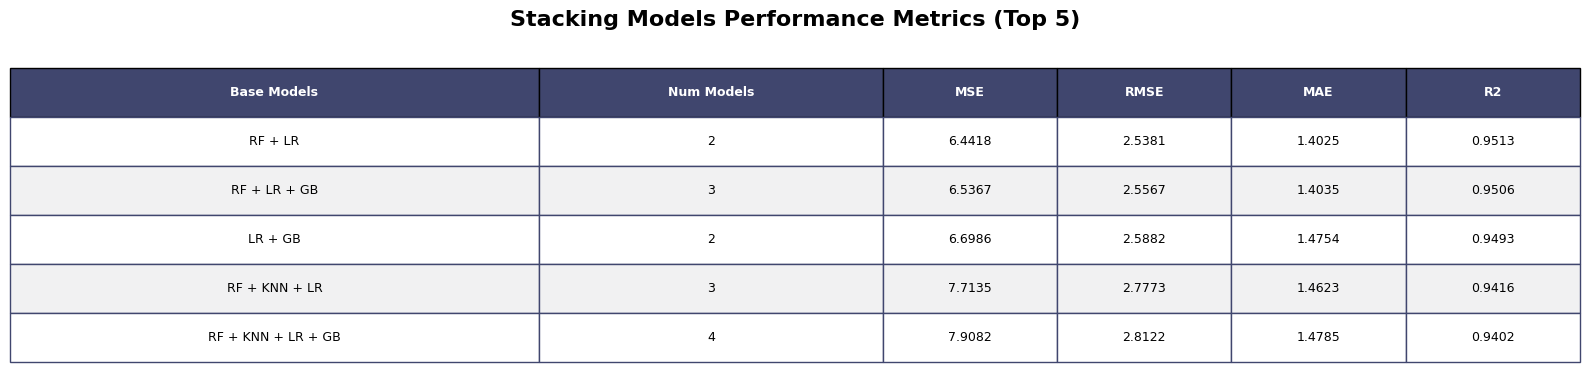

In [65]:
plot_results_table(results_df_WQIInput_retrain)

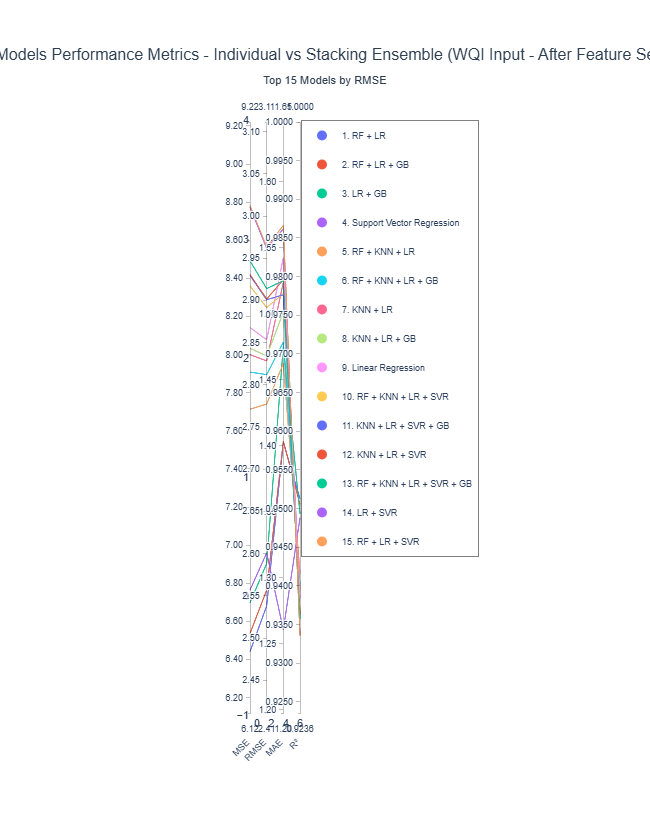

In [66]:
fig_all_models_52 = plot_parallel_coordinates_all_models(
    results_df=results_df_WQIInput_retrain,
    y_test=y_test_WQIInput_retrain,
    rf_pred=rf_pred_WQIInput_retrain,
    gb_pred=gb_pred_WQIInput_retrain,
    lr_pred=lr_pred_WQIInput_retrain,
    knn_pred=knn_pred_WQIInput_retrain,
    svr_pred=svr_pred_WQIInput_retrain,
    title="5.2: All Models Performance Metrics - Individual vs Stacking Ensemble (WQI Input - After Feature Selection)"
)

fig_all_models_52.show()

# 6. Traditional WQI Formula Evaluation

In [67]:
wqi_data_droped_v3 = full_data.copy()
wqi_data_droped_v3.drop({'EColi', 'COD', 'NH4', 'NO3', 'Cd', 'As', 'VN_WQI'}, axis=1, inplace=True)
for metal, bp_points in metal_configs.items():
    if metal in wqi_data_droped_v3.columns:
        new_col_name = f'WQI_{metal.split()[0]}'
        wqi_data_droped_v3[new_col_name] = wqi_data_droped_v3[metal].apply(
            lambda x: calculate_wqi_generic(x, bp_points)
        )
wqi_data_droped_v3['WQI_DO'] = wqi_data_droped_v3.apply(
    lambda row: calculate_wqi_do(row['DO'], row['Temp']), axis=1
)
wqi_data_droped_v3['WQI_pH'] = wqi_data_droped_v3['pH'].apply(calculate_wqi_ph)
for param, bp_points in params_config.items():
    if param in wqi_data_droped_v3.columns:
        # Create a new column name, e.g., WQI_BOD5, WQI_NH4...
        new_col = f"WQI_{param.replace('+', '').replace('-', '')}"
        wqi_data_droped_v3[new_col] = wqi_data_droped_v3[param].apply(
            lambda x: calculate_wqi_formula1(x, bp_points)
        )

# 4. Handle NO2- separately (Because the table only has 2 levels: <=0.05 and >0.05)
if 'NO2' in wqi_data_droped_v3.columns:
    wqi_data_droped_v3['WQI_NO2'] = wqi_data_droped_v3['NO2'].apply(
        lambda x: 100 if x <= 0.05 else 10 if x > 0.05 else np.nan
    )
wqi_data_droped_v3['VN_WQI'] = wqi_data_droped_v3.apply(calculate_final_vn_wqi, axis=1)

In [68]:
y1 = wqi_data_droped_v3['VN_WQI']
y2 = full_data['VN_WQI']
print("Retrained Data - MSE:", mean_squared_error(y2, y1))
print("Retrained Data - RMSE:", np.sqrt(mean_squared_error(y2, y1)))
print("Retrained Data - MAE:", mean_absolute_error(y2, y1))
print("Retrained Data - R^2:", r2_score(y2, y1))

Retrained Data - MSE: 0.0
Retrained Data - RMSE: 0.0
Retrained Data - MAE: 0.0
Retrained Data - R^2: 1.0


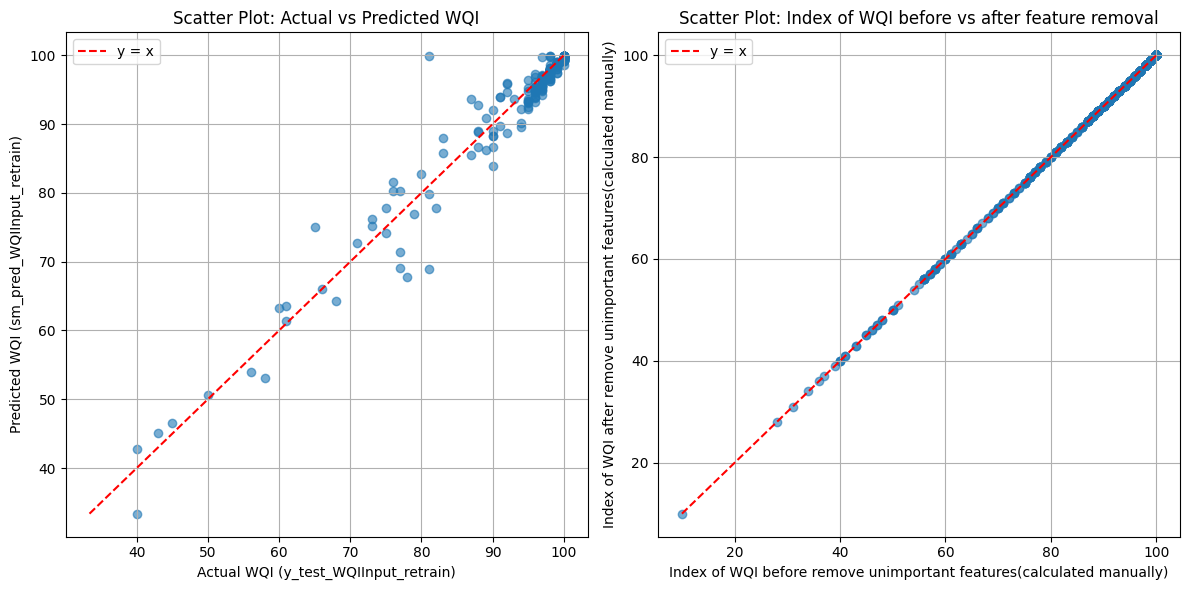

In [69]:
# Side-by-side scatter plots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot 1: Actual vs Predicted WQI
axes[0].scatter(y_test_WQIInput_retrain.values, sm_pred_WQIInput_retrain, alpha=0.6)
min_v1 = min(y_test_WQIInput_retrain.min(), sm_pred_WQIInput_retrain.min())
max_v1 = max(y_test_WQIInput_retrain.max(), sm_pred_WQIInput_retrain.max())
axes[0].plot([min_v1, max_v1], [min_v1, max_v1], 'r--', label='y = x')
axes[0].set_xlabel('Actual WQI (y_test_WQIInput_retrain)')
axes[0].set_ylabel('Predicted WQI (sm_pred_WQIInput_retrain)')
axes[0].set_title('Scatter Plot: Actual vs Predicted WQI')
axes[0].legend()
axes[0].grid(True)

# Plot 2: Manual vs Reduced-feature WQI
manual_index = full_data['VN_WQI']
ml_index = wqi_data_droped_v3['VN_WQI']
axes[1].scatter(manual_index, ml_index, alpha=0.6)
min_v2 = min(manual_index.min(), ml_index.min())
max_v2 = max(manual_index.max(), ml_index.max())
axes[1].plot([min_v2, max_v2], [min_v2, max_v2], 'r--', label='y = x')
axes[1].set_xlabel('Index of WQI before remove unimportant features(calculated manually)')
axes[1].set_ylabel('Index of WQI after remove unimportant features(calculated manually)')
axes[1].set_title('Scatter Plot: Index of WQI before vs after feature removal')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()